# HW2 — Multiple Object Video Detection (VisDrone-VID, UCU AI 2026)
One end-to-end notebook: data understanding → preprocessing → four detector families → final pipeline (+ temporal bonus).

| Grading checkpoint | Section |
|---|---|
| Data Understanding and Preprocessing (1.00) | 1 – 3 |
| One-stage Anchor-free (1.00) | 4 (YOLO11) |
| Two-stage Anchor-based (1.00) | 6 (Faster R-CNN) |
| One-stage Anchor-based (1.00) | 7 (RetinaNet) |
| Query-based (0.75) | 8 (RT-DETR) |
| Your pipeline (1.25) | 9 |
| Bonus: data temporality | 10 |

**Environment.** Google Colab, one Tesla T4 (16 GB), 2 CPU cores. Seeds: `seed=0` (Ultralytics), `torch.manual_seed(0)` (torchvision).

**Protocol shared by every model.**
- *Training data:* every 3rd frame of each of the 56 training clips (8090 frames), longest side resized to 1280 px, ignore regions masked.
- *Validation:* 571 frames (every 5th) of the 7 held-out validation clips — the split is by sequence, never by frame.
- *Metric:* COCO mAP@[.5:.95] (plus AP50 / AP_small / ...) via pycocotools on original-resolution frames; ignore regions are `iscrowd` ground truth, so detections inside them are not penalised; `maxDets = 500` as in the competition.
- *Inference:* `conf = 0.001`, at most 300 detections per frame.

## 0. Setup
To avoid losts of essential info, Google Drive was used

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip -q "/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip" -d "/content/multiple-object-video-detection-hw-2-ucu-ai-2026"


## 1. Data understanding (EDA)
All statistics come from `annotations_coco.json` (no image is read except in the sanity-check plot), so the section runs in seconds on CPU. Every analysis is tied to a design decision made later:

| Analysis | Decision it informs |
|---|---|
| class balance | loss weighting, rare classes (bus, truck) |
| object size and aspect ratio | input resolution, anchor sizes and ratios, focus on small-object AP |
| objects per frame | number of RPN proposals / RT-DETR queries, `max_det` |
| ignore-region coverage | how ignored areas are masked in training |
| frame-to-frame IoU | frame subsampling step |
| train / val / test resolutions | resizing policy, inference scale |

### 1.1 Configuration and helpers

In [2]:
import json, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

ROOT = Path(r"/content/multiple-object-video-detection-hw-2-ucu-ai-2026")

OUT = Path("eda_out"); OUT.mkdir(exist_ok=True)
CLASSES = ["person","bicycle","car","van","truck","tricycle","bus","motor"]
SUMMARY = []
def log(s=""):
    print(s); SUMMARY.append(str(s))
print("ROOT exists:", ROOT.exists())

ROOT exists: False


### 1.2 Load annotations (COCO → dataframes)
COCO `category_id` is 1-based, so `cls = category_id - 1` everywhere (YOLO labels and the submission are 0-based). `iscrowd = 1` marks ignore regions.

In [5]:
def load_split(split):
    d = json.load(open(ROOT/split/"annotations_coco.json", encoding="utf-8"))
    imgs = pd.DataFrame(d["images"]).rename(columns={"id":"image_id"})
    anns = pd.DataFrame(d["annotations"])
    bb = np.array(anns["bbox"].tolist(), dtype=float)
    anns[["x","y","w","h"]] = bb
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id","video","frame_id","width","height"]], on="image_id")
    anns["size"] = np.sqrt(anns["w"]*anns["h"])
    anns["rel_size"] = anns["size"]/np.sqrt(anns["width"]*anns["height"])
    objs, ign = anns[anns.iscrowd==0].copy(), anns[anns.iscrowd==1].copy()
    return d, imgs, objs, ign

data = {s: load_split(s) for s in ["train","val"]}
for s,(d,imgs,objs,ign) in data.items():
    log(f"[{s}] clips={imgs.video.nunique()} frames={len(imgs)} objects={len(objs)} ignore_regions={len(ign)}")
print(data["train"][1].head(3)); print(data["train"][2].head(3))

[train] clips=56 frames=24201 objects=1105516 ignore_regions=510744
[val] clips=7 frames=2846 objects=114132 ignore_regions=31960
   image_id                              file_name  width  height  video_id  \
0         1  images/uav0000013_00000_v/0000001.jpg   1344     756         1   
1         2  images/uav0000013_00000_v/0000002.jpg   1344     756         1   
2         3  images/uav0000013_00000_v/0000003.jpg   1344     756         1   

                video  frame_id  
0  uav0000013_00000_v         1  
1  uav0000013_00000_v         2  
2  uav0000013_00000_v         3  
   id  image_id  category_id                 bbox  area  iscrowd  truncation  \
0   1         1            1   [424, 543, 35, 88]  3080        0         0.0   
1   2         1            1   [416, 530, 36, 85]  3060        0         0.0   
2   3         1            6  [531, 641, 87, 114]  9918        0         1.0   

   occlusion  track_id  orig_category_id  ...      y     w      h  cls  \
0        0.0       2.0

### 1.3 Class distribution (train vs. validation)

Class counts:
           train    val
person    328701  50312
bicycle    40255   6022
car       505301  31821
van        46940   6842
truck      30498   1359
tricycle   41349   5487
bus         9653    264
motor     102819  12025
Class %:
          train    val
person    29.73  44.08
bicycle    3.64   5.28
car       45.71  27.88
van        4.25   5.99
truck      2.76   1.19
tricycle   3.74   4.81
bus        0.87   0.23
motor      9.30  10.54


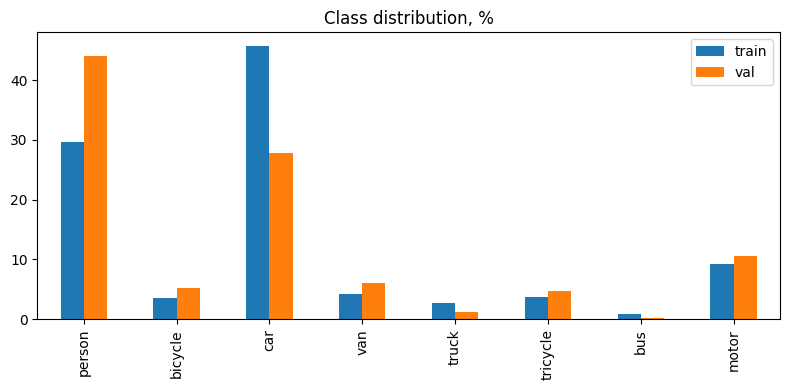

In [6]:
cc = pd.concat({s: data[s][2].cls.value_counts().reindex(range(8), fill_value=0) for s in data}, axis=1)
cc.index = CLASSES
cc_pct = (cc/cc.sum()*100).round(2)
log("Class counts:\n" + cc.to_string()); log("Class %:\n" + cc_pct.to_string())
cc_pct.plot.bar(figsize=(8,4), title="Class distribution, %"); plt.tight_layout()
plt.savefig(OUT/"class_dist.png", dpi=120); plt.show()

### 1.4 Object sizes and aspect ratios
Size = sqrt(w·h) in original pixels; COCO buckets: small < 32, medium 32–96, large > 96. The aspect-ratio quantiles feed the anchor configuration.

Size quantiles (px, train):
count    1105516.0
mean          56.6
std           38.3
min            7.7
5%            19.7
25%           32.0
50%           45.8
75%           67.9
95%          130.2
max          703.0
Size buckets %:
bucket
medium    63.5
small     24.9
large     11.6
Bucket % per class:
bucket    small  medium  large
cls                           
bicycle    24.4    74.1    1.5
bus         4.1    39.1   56.8
car        16.4    64.5   19.1
motor      30.4    68.2    1.4
person     39.5    60.2    0.3
tricycle   21.1    66.1   12.8
truck       9.4    57.9   32.7
van        21.5    62.7   15.9
Median size per class (px):
cls
bicycle      41.4
bus         113.4
car          57.0
motor        40.2
person       35.8
tricycle     54.9
truck        73.5
van          49.8
Share of objects with size < 16 px: 2.2%, < 10 px: 0.0%


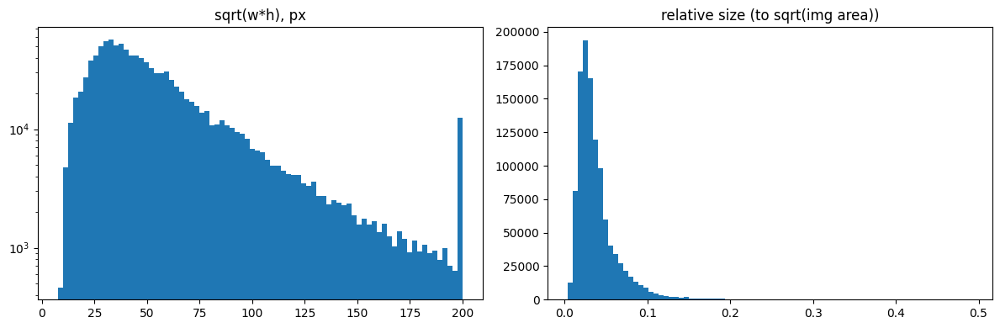

Aspect ratio w/h quantiles:
count    1105516.00
mean           1.11
std            0.67
min            0.03
5%             0.39
25%            0.59
50%            0.95
75%            1.46
95%            2.45
max           25.17
Aspect ratio median per class:
cls
bicycle     0.95
bus         1.03
car         1.25
motor       0.80
person      0.50
tricycle    1.06
truck       1.08
van         1.11


In [7]:
tr = data["train"][2]
def bucket(s): return pd.cut(s, [0,32,96,1e9], labels=["small","medium","large"])
tr["bucket"] = bucket(tr["size"])
log("Size quantiles (px, train):\n" + tr["size"].describe(percentiles=[.05,.25,.5,.75,.95]).round(1).to_string())
log("Size buckets %:\n" + (tr.bucket.value_counts(normalize=True)*100).round(1).to_string())
bc = pd.crosstab(tr.cls.map(dict(enumerate(CLASSES))), tr.bucket, normalize="index").mul(100).round(1)
log("Bucket % per class:\n" + bc.to_string())
log("Median size per class (px):\n" + tr.groupby(tr.cls.map(dict(enumerate(CLASSES))))["size"].median().round(1).to_string())
log("Share of objects with size < 16 px: %.1f%%, < 10 px: %.1f%%" % ((tr["size"]<16).mean()*100, (tr["size"]<10).mean()*100))

fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].hist(tr["size"].clip(0,200), bins=80); ax[0].set_title("sqrt(w*h), px"); ax[0].set_yscale("log")
ax[1].hist(tr["rel_size"], bins=80); ax[1].set_title("relative size (to sqrt(img area))")
plt.tight_layout(); plt.savefig(OUT/"sizes.png", dpi=120); plt.show()

tr["ar"] = tr["w"]/tr["h"]
log("Aspect ratio w/h quantiles:\n" + tr["ar"].describe(percentiles=[.05,.25,.5,.75,.95]).round(2).to_string())
log("Aspect ratio median per class:\n" + tr.groupby(tr.cls.map(dict(enumerate(CLASSES))))["ar"].median().round(2).to_string())

### 1.5 Scene density (objects per frame)

Objects per frame (train):
count    24201.0
mean        45.7
std         31.6
min          0.0
50%         43.0
90%         92.0
99%        142.0
max        180.0
Frames with 0 objects: 3
Frames with >100 objects: 7.6%, >200: 0.0%, max=180


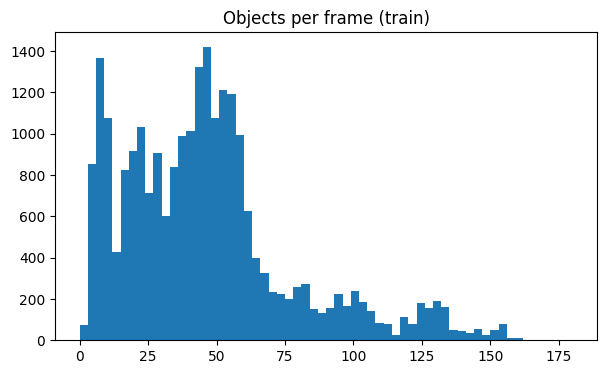

In [8]:
d,imgs,objs,ign = data["train"]
per_frame = objs.groupby("image_id").size().reindex(imgs.image_id, fill_value=0)
log("Objects per frame (train):\n" + per_frame.describe(percentiles=[.5,.9,.99]).round(1).to_string())
log("Frames with 0 objects: %d" % (per_frame==0).sum())
log("Frames with >100 objects: %.1f%%, >200: %.1f%%, max=%d" % ((per_frame>100).mean()*100, (per_frame>200).mean()*100, per_frame.max()))
plt.figure(figsize=(7,4)); plt.hist(per_frame, bins=60); plt.title("Objects per frame (train)")
plt.savefig(OUT/"objs_per_frame.png", dpi=120); plt.show()

### 1.6 Per-clip statistics
Resolution, density, median object size, dominant class and ignore coverage per clip — shows how the data varies across sequences.

In [9]:
def clip_table(split):
    d,imgs,objs,ign = data[split]
    pf = objs.groupby("image_id").size().reindex(imgs.image_id, fill_value=0).rename("n").reset_index()
    pf = pf.merge(imgs[["image_id","video"]], on="image_id")
    g = pd.DataFrame({
        "frames": imgs.groupby("video").size(),
        "res": imgs.groupby("video").apply(lambda x: f"{x.width.iloc[0]}x{x.height.iloc[0]}"),
        "obj/frame": pf.groupby("video").n.mean().round(1),
        "med_size": objs.groupby("video")["size"].median().round(1),
        "top_class": objs.groupby("video").cls.agg(lambda s: CLASSES[s.value_counts().idxmax()]),
        "ignore_frames%": (ign.groupby("video").image_id.nunique()/imgs.groupby("video").size()*100).reindex(imgs.video.unique()).fillna(0).round(0),
    })
    return g
for s in ["train","val"]:
    t = clip_table(s); log(f"\n=== clip table: {s} ===\n" + t.to_string())

/tmp/ipykernel_402/1702378210.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "res": imgs.groupby("video").apply(lambda x: f"{x.width.iloc[0]}x{x.height.iloc[0]}"),



=== clip table: train ===
                    frames        res  obj/frame  med_size top_class  ignore_frames%
video                                                                               
uav0000013_00000_v     269   1344x756       28.9      41.7    person           100.0
uav0000013_01073_v      58   1344x756       17.7      54.3    person           100.0
uav0000013_01392_v     118   1344x756       23.8      44.8    person           100.0
uav0000020_00406_v     501   1344x756       18.7      42.7    person           100.0
uav0000071_03240_v     181  1904x1071       30.0      56.3    person           100.0
uav0000072_04488_v      85  1904x1071      110.4      45.8    person             0.0
uav0000072_05448_v     217  1904x1071       47.7      54.7    person            65.0
uav0000072_06432_v      97  1904x1071       89.9      42.3    person           100.0
uav0000076_00720_v     361  1904x1071       19.7      86.5    person             0.0
uav0000079_00480_v     361  1904x1071 

/tmp/ipykernel_402/1702378210.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "res": imgs.groupby("video").apply(lambda x: f"{x.width.iloc[0]}x{x.height.iloc[0]}"),


### 1.7 Ignore regions
Share of frames with ignore regions, regions per frame and the image area they cover.

In [10]:
for s in ["train","val"]:
    d,imgs,objs,ign = data[s]
    frac_frames = ign.image_id.nunique()/len(imgs)*100
    area_share = (ign.w*ign.h/(ign.width*ign.height)).groupby(ign.image_id).sum()
    log(f"[{s}] frames with ignore: {frac_frames:.1f}%, regions/frame (where present): {len(ign)/max(ign.image_id.nunique(),1):.1f}, "
        f"median image-area share covered: {area_share.median()*100:.1f}%, max: {area_share.max()*100:.1f}%")

[train] frames with ignore: 74.7%, regions/frame (where present): 28.2, median image-area share covered: 13.2%, max: 308.2%
[val] frames with ignore: 50.4%, regions/frame (where present): 22.3, median image-area share covered: 11.5%, max: 88.6%


### 1.8 Occlusion and truncation

In [10]:
for col in ["occlusion","truncation"]:
    log(f"{col} value counts (train, %):\n" + (tr[col].value_counts(normalize=True)*100).round(1).sort_index().to_string())

occlusion value counts (train, %):
occlusion
0.0    54.3
1.0    40.3
2.0     5.3
truncation value counts (train, %):
truncation
0.0    95.7
1.0     4.3


### 1.9 Temporal redundancy: IoU of the same object between frames t and t+k
Objects are matched across frames by `track_id`. A high IoU means neighbouring frames are near-duplicates, which justifies frame subsampling.

In [11]:
def iou(a, b):
    ax2, ay2, bx2, by2 = a.x+a.w, a.y+a.h, b.x+b.w, b.y+b.h
    iw = (np.minimum(ax2,bx2)-np.maximum(a.x,b.x)).clip(0); ih = (np.minimum(ay2,by2)-np.maximum(a.y,b.y)).clip(0)
    inter = iw*ih; return inter/(a.w*a.h + b.w*b.h - inter + 1e-9)

A = tr[["video","track_id","frame_id","x","y","w","h","size"]]
res = {}
for k in [1,2,3,5,10]:
    B = A.copy(); B["frame_id"] -= k
    m = A.merge(B, on=["video","track_id","frame_id"], suffixes=("","_n"))
    a = m[["x","y","w","h"]]; b = m[["x_n","y_n","w_n","h_n"]].set_axis(["x","y","w","h"], axis=1)
    v = iou(a,b); small = m["size"]<32
    res[k] = dict(median_IoU=round(v.median(),3), median_IoU_small=round(v[small].median(),3), pairs=len(m))
log("Median IoU of the same object between frame t and t+k:\n" + pd.DataFrame(res).T.to_string())
tl = tr.groupby(["video","track_id"]).size()
log("Track length (frames): median=%d, mean=%.0f" % (tl.median(), tl.mean()))

Median IoU of the same object between frame t and t+k:
    median_IoU  median_IoU_small      pairs
1        0.897             0.871  1097628.0
2        0.810             0.771  1090077.0
3        0.731             0.680  1082554.0
5        0.597             0.528  1067598.0
10       0.357             0.263  1031089.0
Track length (frames): median=103, mean=151


### 1.10 Test set and resolution shift
Image sizes of train, val and test clips (the test set is dominated by smaller resolutions than train).

In [12]:
te = pd.read_csv(ROOT/"test_images.csv")
tt = te.groupby("clip").agg(frames=("image_id","size"), w=("width","first"), h=("height","first"))
log("Test: %d images, %d clips" % (len(te), te['clip'].nunique()))
log("Test resolutions (clips):\n" + (tt.w.astype(str)+"x"+tt.h.astype(str)).value_counts().to_string())
for s in ["train","val"]:
    im = data[s][1]
    log(f"{s} resolutions (clips):\n" + im.groupby("video").apply(lambda x: f"{x.width.iloc[0]}x{x.height.iloc[0]}").value_counts().to_string())


Test: 3811 images, 48 clips
Test resolutions (clips):
1360x764     18
1920x1080    11
1344x756      7
960x540       5
1904x1072     4
680x382       3
train resolutions (clips):
1904x1071    30
1344x756     11
2688x1512    11
2720x1530     2
1920x1080     1
1360x765      1
val resolutions (clips):
1344x756     2
1904x1071    2
2720x1530    1
2688x1512    1
3840x2160    1


/tmp/ipykernel_402/2788285571.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  log(f"{s} resolutions (clips):\n" + im.groupby("video").apply(lambda x: f"{x.width.iloc[0]}x{x.height.iloc[0]}").value_counts().to_string())
/tmp/ipykernel_402/2788285571.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  log(f"{s} resolutions (clips):\n" + im.groupby("video").apply(lambda x: f"{x.width.iloc[0]}x{x.height.ilo

### 1.11 Ground-truth sanity check
Boxes are coloured by class; ignore regions are outlined in red.

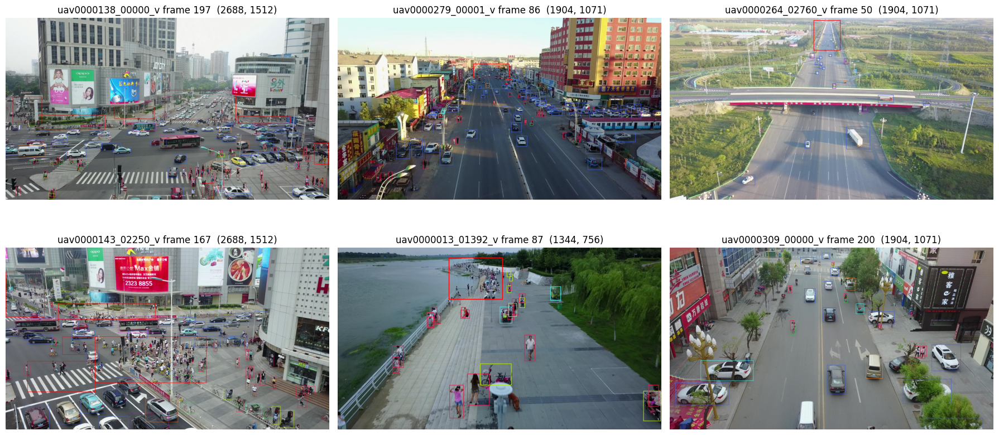

In [13]:
PALETTE = ["#e6194b","#3cb44b","#4363d8","#f58231","#911eb4","#46f0f0","#f032e6","#bcf60c"]
d,imgs,objs,ign = data["train"]

def find_image(row, split="train"):
    base = Path(row["file_name"]).name
    for c in [ROOT/split/row["file_name"], ROOT/split/"images"/row["video"]/base, ROOT/row["file_name"]]:
        if c.exists(): return c
    return None

rng = np.random.default_rng(0)
vids = rng.choice(imgs.video.unique(), 6, replace=False)
fig, axs = plt.subplots(2,3, figsize=(18,9))
for ax, v in zip(axs.ravel(), vids):
    row = imgs[imgs.video==v].sample(1, random_state=0).iloc[0]
    p = find_image(row)
    if p is None: ax.set_title(f"{v}: image not found ({row['file_name']})"); continue
    im = Image.open(p).convert("RGB"); dr = ImageDraw.Draw(im)
    for r in ign[ign.image_id==row.image_id].itertuples(): dr.rectangle([r.x,r.y,r.x+r.w,r.y+r.h], outline="red", width=3)
    for r in objs[objs.image_id==row.image_id].itertuples(): dr.rectangle([r.x,r.y,r.x+r.w,r.y+r.h], outline=PALETTE[r.cls], width=2)
    ax.imshow(im); ax.set_title(f"{v} frame {row.frame_id}  {im.size}"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT/"gt_samples.png", dpi=100); plt.show()

## 2. Preprocessing
1. **Sequence split.** The provided `train/` (56 clips) and `val/` (7 clips) are disjoint by sequence, so there is no frame-level leakage.
2. **Frame subsampling.** Every 3rd frame inside each clip for training, every 5th for validation (justified by the frame-to-frame IoU analysis in 1.9).
3. **Resize.** Longest side → 1280 px (area interpolation, no upscaling). Pixel normalisation is done by the training frameworks.
4. **Ignored regions.** Filled with grey (114) in training images; pixels of labelled objects that overlap an ignore region are restored, so ground-truth objects are never damaged. Validation images used for the in-training proxy metric are always masked; the final metric uses original unmasked frames with the COCO `iscrowd` mechanism.
5. **Conversion.** COCO → YOLO txt (`class cx cy w h`, normalised), `category_id - 1`; degenerate boxes (< 1 px) are dropped. There are no non-target classes in this release: the 8 target classes are kept and VisDrone's “others” became ignore regions.
6. **Augmentation.** Ultralytics defaults for YOLO and RT-DETR (mosaic, HSV, scale, flip; mosaic is switched off for the last epochs); horizontal flip only for the torchvision detectors.
7. All steps are deterministic (fixed frame selection, no randomness in preprocessing).

### 2.1 Configuration
`TRAIN_STEP`, `VAL_STEP`, `LONG_SIDE` and `MASK_IGNORE` control the dataset variant; `MASK_IGNORE = False` produces the no-mask variant used in the data ablation.

In [14]:
import time
from concurrent.futures import ThreadPoolExecutor
import cv2

TRAIN_STEP  = 3
VAL_STEP    = 5
LONG_SIDE   = 1280
MASK_IGNORE = True
JPEG_Q      = 92
GRAY        = 114

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("/content/work")
WORK.mkdir(parents=True, exist_ok=True)
DS = WORK / f"ds_s{TRAIN_STEP}_{'mask' if MASK_IGNORE else 'nomask'}"
print("ROOT:", ROOT, "\nDS:", DS)

ROOT: /content/multiple-object-video-detection-hw-2-ucu-ai-2026 
DS: /content/work/ds_s3_mask


### 2.2 Frame selection and image index
A `(clip, frame) → path` index makes the pipeline independent of how `file_name` is written in the COCO file.

In [15]:
def build_index(split):
    idx = {}
    for clip_dir in (ROOT/split/"images").iterdir():
        if clip_dir.is_dir():
            for f in clip_dir.iterdir(): idx[(clip_dir.name, f.stem)] = f
    return idx

def load_split(split, step):
    d = json.load(open(ROOT/split/"annotations_coco.json", encoding="utf-8"))
    imgs = pd.DataFrame(d["images"]).rename(columns={"id":"image_id"})
    imgs["pos"] = imgs.groupby("video").frame_id.rank(method="first").astype(int) - 1
    sel = imgs[imgs.pos % step == 0].copy()
    anns = pd.DataFrame(d["annotations"])
    anns = anns[anns.image_id.isin(sel.image_id)]
    by_img = {k: g for k, g in anns.groupby("image_id")}
    return d, sel, by_img

def make_records(split, step):
    d, sel, by_img = load_split(split, step)
    idx = build_index(split)
    recs, missing = [], 0
    for r in sel.itertuples():
        p = Path(r.file_name)
        clip = p.parent.name if p.parent.name not in ("", ".") else r.video
        src = idx.get((clip, p.stem)) or idx.get((r.video, p.stem))
        if src is None: missing += 1; continue
        g = by_img.get(r.image_id)
        boxes, ign = [], []
        if g is not None:
            for a in g.itertuples():
                (ign if a.iscrowd == 1 else boxes).append((a.category_id-1, *a.bbox))
        recs.append(dict(split=split, src=src, name=f"{r.video}__{p.stem}", W=r.width, H=r.height,
                         boxes=boxes, ign=[b[1:] for b in ign]))
    print(f"[{split}] step={step}: selected={len(sel)} found={len(recs)} missing={missing}")
    return d, sel, recs

d_tr, sel_tr, rec_tr = make_records("train", TRAIN_STEP)
d_va, sel_va, rec_va = make_records("val",   VAL_STEP)
assert len(rec_tr) > 0 and len(rec_va) > 0, "Image not found"

[train] step=3: selected=8090 found=8090 missing=0
[val] step=5: selected=571 found=571 missing=0


### 2.3 Resize, mask ignore regions, write YOLO labels
Runs on CPU. Status `ok` means the decoded image size matches the annotation size.

In [16]:
def process(rec, mask):
    img = cv2.imread(str(rec["src"]))
    if img is None: return "read_fail"
    H, W = img.shape[:2]
    status = "ok" if (W, H) == (rec["W"], rec["H"]) else "size_mismatch"
    s = min(1.0, LONG_SIDE / max(W, H))
    if s < 1: img = cv2.resize(img, (round(W*s), round(H*s)), interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]

    def sl(x, y, bw, bh):
        return (slice(max(int(y*s), 0), min(int(np.ceil((y+bh)*s)), h)),
                slice(max(int(x*s), 0), min(int(np.ceil((x+bw)*s)), w)))
    if mask and rec["ign"]:
        orig = img.copy()
        for x, y, bw, bh in rec["ign"]: img[sl(x, y, bw, bh)] = GRAY
        for _, x, y, bw, bh in rec["boxes"]: img[sl(x, y, bw, bh)] = orig[sl(x, y, bw, bh)]

    lines = []
    for c, x, y, bw, bh in rec["boxes"]:
        x1, y1, x2, y2 = max(x, 0), max(y, 0), min(x+bw, W), min(y+bh, H)
        if x2-x1 < 1 or y2-y1 < 1: continue
        lines.append(f"{int(c)} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
    sp = rec["split"]
    cv2.imwrite(str(DS/"images"/sp/f"{rec['name']}.jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, JPEG_Q])
    (DS/"labels"/sp/f"{rec['name']}.txt").write_text("\n".join(lines))
    return status

def run(recs, mask):
    for sp in {r["split"] for r in recs}:
        (DS/"images"/sp).mkdir(parents=True, exist_ok=True); (DS/"labels"/sp).mkdir(parents=True, exist_ok=True)
    t = time.time()
    with ThreadPoolExecutor(4) as ex: res = list(ex.map(lambda r: process(r, mask), recs))
    print(pd.Series(res).value_counts().to_dict(), f"{time.time()-t:.0f}s")

run(rec_tr, MASK_IGNORE)
run(rec_va, True)

{'ok': 8090} 293s
{'ok': 571} 26s


### 2.4 `data.yaml` and the validation subset in COCO format
`val_subset_coco.json` keeps the original pixel coordinates and the `iscrowd` regions; it is the ground truth for the final pycocotools evaluation.

In [17]:
yaml = f"""path: {DS.resolve()}
train: images/train
val: images/val
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
"""
(DS/"data.yaml").write_text(yaml)

keep = set(sel_va.image_id)
coco_val = {"images": [i for i in d_va["images"] if i["id"] in keep],
            "annotations": [a for a in d_va["annotations"] if a["image_id"] in keep],
            "categories": d_va["categories"]}
json.dump(coco_val, open(DS/"val_subset_coco.json", "w"))
meta = dict(TRAIN_STEP=TRAIN_STEP, VAL_STEP=VAL_STEP, LONG_SIDE=LONG_SIDE, MASK_IGNORE=MASK_IGNORE,
            n_train=len(rec_tr), n_val=len(rec_va))
json.dump(meta, open(DS/"prep_meta.json", "w")); print(meta)
print(yaml)

{'TRAIN_STEP': 3, 'VAL_STEP': 5, 'LONG_SIDE': 1280, 'MASK_IGNORE': True, 'n_train': 8090, 'n_val': 571}
path: /content/work/ds_s3_mask
train: images/train
val: images/val
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]



### 2.5 Verify the conversion visually
Processed training frames with the converted YOLO labels drawn on top; grey areas are masked ignore regions.

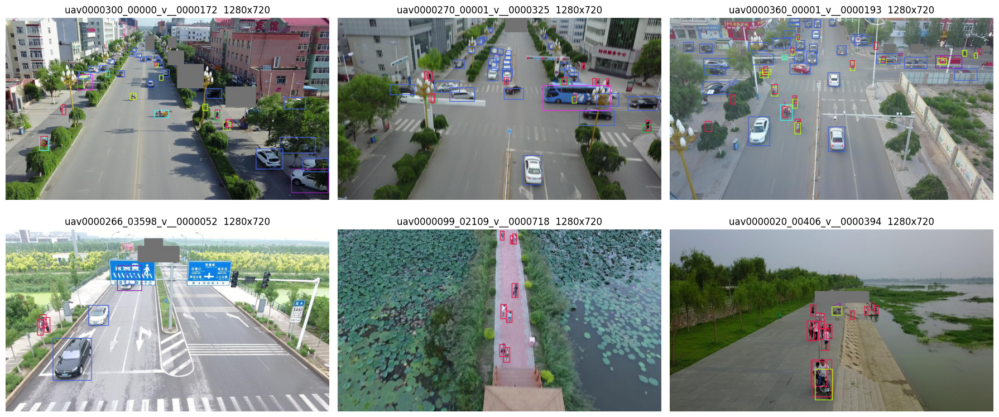

In [18]:
PAL = [(230,25,75),(60,180,75),(67,99,216),(245,130,49),(145,30,180),(70,240,240),(240,50,230),(188,246,12)]
rng = np.random.default_rng(1)
pick = rng.choice(len(rec_tr), 6, replace=False)
fig, axs = plt.subplots(2, 3, figsize=(18, 8))
for ax, i in zip(axs.ravel(), pick):
    n = rec_tr[i]["name"]
    im = cv2.cvtColor(cv2.imread(str(DS/"images/train"/f"{n}.jpg")), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for ln in (DS/"labels/train"/f"{n}.txt").read_text().splitlines():
        c, cx, cy, bw, bh = ln.split(); c = int(c); cx, cy, bw, bh = map(float, (cx, cy, bw, bh))
        cv2.rectangle(im, (int((cx-bw/2)*w), int((cy-bh/2)*h)), (int((cx+bw/2)*w), int((cy+bh/2)*h)), PAL[c], 2)
    ax.imshow(im); ax.set_title(f"{n}  {w}x{h}"); ax.axis("off")
plt.tight_layout(); plt.savefig(WORK/"prep_check.png", dpi=90); plt.show()

### 2.6 Dataset statistics after preprocessing

In [19]:
def stats(sp):
    labs = list((DS/"labels"/sp).glob("*.txt"))
    cls = pd.Series([int(l.split()[0]) for f in labs for l in f.read_text().splitlines() if l])
    size_gb = sum(f.stat().st_size for f in (DS/"images"/sp).glob("*.jpg")) / 1e9
    print(f"{sp}: frames={len(labs)} objects={len(cls)} images={size_gb:.2f} GB")
    print((cls.value_counts(normalize=True).sort_index()*100).round(1).rename(dict(enumerate(
        ["person","bicycle","car","van","truck","tricycle","bus","motor"]))).to_dict())
stats("train"); stats("val")

train: frames=8090 objects=370072 images=2.08 GB
{'person': 29.8, 'bicycle': 3.6, 'car': 45.7, 'van': 4.2, 'truck': 2.8, 'tricycle': 3.7, 'bus': 0.9, 'motor': 9.3}
val: frames=571 objects=22906 images=0.14 GB
{'person': 44.0, 'bicycle': 5.3, 'car': 27.9, 'van': 6.0, 'truck': 1.2, 'tricycle': 4.8, 'bus': 0.2, 'motor': 10.6}


## 3. Shared utilities (evaluation protocol)
Every detector is evaluated by the same code:
- `coco_eval` — mAP@[.5:.95], AP50, AP75, AP small / medium / large and per-class AP (pycocotools, original unmasked validation frames, `iscrowd` regions, `maxDets = 500`).
- `eval_report` — overall metrics plus a per-clip table (mAP, density, median object size).
- `predict_items`, `predict_test`, `write_submission`, `check_submission` — inference loop and the submission writer (`class score x y w h`, 0-based class, pixel coordinates of the original image) with a format check.
- `analyze_failures`, `draw_case` — error taxonomy (TP, class confusion, false positive outside ignore regions, FN, small-object FN) and its visualisation.
- `prepare_ds`, `get_ds` — dataset preparation (same logic as section 2).
- `backup` — copies weights, predictions and metrics to Google Drive.

### 3.1 Install dependencies

In [21]:
!pip install -q ultralytics pycocotools

### 3.2 Utilities

In [22]:
import time
import numpy as np, pandas as pd, cv2
import contextlib, io, json, pickle
from collections import defaultdict
from pathlib import Path

NAME = "multiple-object-video-detection-hw-2-ucu-ai-2026"
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("/content/work")
WORK.mkdir(parents=True, exist_ok=True)


def find_root():
    cands = [Path("/kaggle/input") / NAME, Path("/kaggle/input/competitions") / NAME, Path("/content") / NAME]
    for c in cands:
        if (c / "test_images.csv").exists():
            return c
    raise FileNotFoundError("test images not found")

def find_ds(name="ds_s3_mask"):
    cands = [WORK / name]
    for c in cands:
        if (c / "val_subset_coco.json").exists():
            return c
    raise FileNotFoundError(f"{name} not found")


ROOT = find_root()


def make_yaml(ds):
    y = WORK / f"{Path(ds).name}.yaml"
    y.write_text(f'path: {Path(ds).resolve()}\ntrain: images/train\nval: images/val\nnc: 8\nnames: {CLASSES}\n'.replace("'", '"'))
    return y

def _index(split):
    idx = {}
    for d in (ROOT / split / "images").iterdir():
        if d.is_dir():
            for f in d.iterdir():
                idx[(d.name, f.stem)] = f
    return idx


def load_val_gt(ds):
    from pycocotools.coco import COCO
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(Path(ds) / "val_subset_coco.json"))


def val_items(gt):
    idx, items = _index("val"), []
    for iid, info in gt.imgs.items():
        p = Path(info["file_name"])
        clip = p.parent.name if p.parent.name not in ("", ".") else info["video"]
        items.append((iid, idx.get((clip, p.stem)) or idx[(info["video"], p.stem)], info["video"]))
    return sorted(items)


def predict_items(predict_fn, items):
    preds, t = [], time.time()
    for iid, path, _ in items:
        b, s, l = predict_fn(path)
        for bb, ss, ll in zip(b, s, l):
            preds.append(dict(image_id=int(iid), category_id=int(ll) + 1, score=float(ss),
                              bbox=[float(bb[0]), float(bb[1]), float(bb[2] - bb[0]), float(bb[3] - bb[1])]))
    return preds, (time.time() - t) / max(len(items), 1) * 1000


def coco_eval(gt, preds, img_ids=None, per_class=False):
    from pycocotools.cocoeval import COCOeval
    keys = ["mAP", "AP50", "AP75", "APs", "APm", "APl"]
    if not preds:
        return {k: 0.0 for k in keys}
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(preds), "bbox")
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        E.params.maxDets = [1, 10, 500]
        E.evaluate(); E.accumulate()
    prec = E.eval["precision"]

    def ap(t=None, a=0, k=None):
        p = prec[:, :, :, a, -1] if k is None else prec[:, :, k:k + 1, a, -1]
        if t is not None:
            p = p[t:t + 1]
        p = p[p > -1]
        return float(p.mean()) if p.size else float("nan")

    out = dict(mAP=ap(), AP50=ap(t=0), AP75=ap(t=5), APs=ap(a=1), APm=ap(a=2), APl=ap(a=3))
    if per_class:
        for k, c in enumerate(CLASSES):
            out[f"AP_{c}"] = ap(k=k)
    return out


def eval_report(gt, preds, items):
    overall = coco_eval(gt, preds, per_class=True)
    rows = []
    for v in sorted({v for _, _, v in items}):
        ids = [i for i, _, vv in items if vv == v]
        r = coco_eval(gt, preds, img_ids=ids)
        anns = [a for i in ids for a in gt.imgToAnns[i] if not a.get("iscrowd", 0)]
        rows.append(dict(clip=v, frames=len(ids), obj_per_frame=len(anns) / len(ids),
                         med_size=float(np.median([np.sqrt(a["bbox"][2] * a["bbox"][3]) for a in anns])) if anns else np.nan,
                         mAP=r["mAP"], AP50=r["AP50"], APs=r["APs"]))
    return overall, pd.DataFrame(rows).round(3)


def log_result(row, path=None):
    path = Path(path or WORK / "results_all.csv")
    df = pd.DataFrame([row])
    if path.exists():
        df = pd.concat([pd.read_csv(path), df], ignore_index=True)
    df.to_csv(path, index=False)
    return df

def predict_test(predict_fn):
    te = pd.read_csv(ROOT / "test_images.csv")
    return {r.image_id: predict_fn(ROOT / r.file_name) for r in te.itertuples()}


def write_submission(out, path=None, max_det=500):
    te = pd.read_csv(ROOT / "test_images.csv")
    rows = []
    for r in te.itertuples():
        b, s, l = out[r.image_id]
        parts = []
        for i in np.argsort(-np.asarray(s))[:max_det]:
            x1, y1 = max(float(b[i][0]), 0), max(float(b[i][1]), 0)
            x2, y2 = min(float(b[i][2]), r.width), min(float(b[i][3]), r.height)
            if x2 - x1 >= 1 and y2 - y1 >= 1:
                parts.append(f"{int(l[i])} {float(s[i]):.5f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}")
        rows.append((r.image_id, " ".join(parts)))
    path = Path(path or WORK / "submission.csv")
    pd.DataFrame(rows, columns=["image_id", "PredictionString"]).to_csv(path, index=False)
    return path


def check_submission(path):
    """Format check: all image_ids present, token count divisible by 6 (sample_submission.csv is optional)."""
    sub = pd.read_csv(path, keep_default_na=False)
    ref_path = ROOT / "sample_submission.csv"
    ref = pd.read_csv(ref_path if ref_path.exists() else ROOT / "test_images.csv", keep_default_na=False)
    assert "image_id" in sub.columns and "PredictionString" in sub.columns, "unexpected columns"
    assert set(sub.image_id) == set(ref.image_id) and len(sub) == len(ref), "image_id mismatch"
    assert (sub.PredictionString.map(lambda s: len(s.split()) % 6) == 0).all(), "token count not divisible by 6"
    n = sub.PredictionString.map(lambda s: len(s.split()) // 6)
    print(f"OK: {len(sub)} rows, detections/frame: mean={n.mean():.1f} max={n.max()}, empty={int((n == 0).sum())}")


def save_preds(obj, name):
    with open(WORK / name, "wb") as f:
        pickle.dump(obj, f)

def analyze_failures(gt, preds, items, thr=0.3, iou_thr=0.5):
    by = defaultdict(list)
    for p in preds:
        if p["score"] >= thr:
            by[p["image_id"]].append(p)
    xyxy = lambda b: np.array([b[0], b[1], b[0] + b[2], b[1] + b[3]], float)
    rows = []
    for iid, _, vid in items:
        anns = gt.imgToAnns.get(iid, [])
        g = [a for a in anns if not a.get("iscrowd", 0)]
        cr = [a["bbox"] for a in anns if a.get("iscrowd", 0)]
        gb = np.array([xyxy(a["bbox"]) for a in g]).reshape(-1, 4)
        ga = (gb[:, 2] - gb[:, 0]) * (gb[:, 3] - gb[:, 1])
        used, tp, conf, fp = set(), 0, 0, 0
        for p in sorted(by.get(iid, []), key=lambda p: -p["score"]):
            db = xyxy(p["bbox"])
            if len(gb):
                iw = (np.minimum(gb[:, 2], db[2]) - np.maximum(gb[:, 0], db[0])).clip(0)
                ih = (np.minimum(gb[:, 3], db[3]) - np.maximum(gb[:, 1], db[1])).clip(0)
                inter = iw * ih
                iou = inter / (ga + (db[2] - db[0]) * (db[3] - db[1]) - inter + 1e-9)
                if used:
                    iou[list(used)] = -1
                j = int(iou.argmax())
                if iou[j] >= iou_thr:
                    used.add(j)
                    if g[j]["category_id"] == p["category_id"]:
                        tp += 1
                    else:
                        conf += 1
                    continue
            cx, cy = (db[0] + db[2]) / 2, (db[1] + db[3]) / 2
            if not any(c[0] <= cx <= c[0] + c[2] and c[1] <= cy <= c[1] + c[3] for c in cr):
                fp += 1
        fn = [j for j in range(len(g)) if j not in used]
        small = sum(1 for j in fn if np.sqrt(g[j]["bbox"][2] * g[j]["bbox"][3]) < 32)
        rows.append(dict(image_id=iid, video=vid, n_gt=len(g), TP=tp, CONF=conf, FP=fp, FN=len(fn), FN_small=small))
    return pd.DataFrame(rows)


def draw_case(gt, preds, iid, path, thr=0.3):
    im = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    t = max(2, im.shape[1] // 700)
    for a in gt.imgToAnns.get(iid, []):
        x, y, w, h = map(int, a["bbox"])
        cv2.rectangle(im, (x, y), (x + w, y + h), (255, 215, 0) if a.get("iscrowd", 0) else (0, 200, 0), t)
    for p in preds:
        if p["image_id"] == iid and p["score"] >= thr:
            x, y, w, h = map(int, p["bbox"])
            cv2.rectangle(im, (x, y), (x + w, y + h), (255, 0, 0), max(1, t - 1))
    return im

def prepare_ds(train_step=3, val_step=5, long_side=1280, mask=True, jpeg_q=92, gray=114):
    from concurrent.futures import ThreadPoolExecutor
    ds = WORK / f"ds_s{train_step}_{'mask' if mask else 'nomask'}"

    def records(split, step):
        d = json.load(open(ROOT / split / "annotations_coco.json", encoding="utf-8"))
        imgs = pd.DataFrame(d["images"]).rename(columns={"id": "image_id"})
        imgs["pos"] = imgs.groupby("video").frame_id.rank(method="first").astype(int) - 1
        sel = imgs[imgs.pos % step == 0]
        anns = pd.DataFrame(d["annotations"])
        anns = anns[anns.image_id.isin(sel.image_id)]
        by = {k: g for k, g in anns.groupby("image_id")}
        idx, recs = _index(split), []
        for r in sel.itertuples():
            p = Path(r.file_name)
            clip = p.parent.name if p.parent.name not in ("", ".") else r.video
            src = idx.get((clip, p.stem)) or idx.get((r.video, p.stem))
            if src is None:
                continue
            boxes, ign = [], []
            g = by.get(r.image_id)
            if g is not None:
                for a in g.itertuples():
                    (ign if a.iscrowd == 1 else boxes).append((a.category_id - 1, *a.bbox))
            recs.append(dict(split=split, src=src, name=f"{r.video}__{p.stem}", W=r.width, H=r.height,
                             boxes=boxes, ign=[b[1:] for b in ign]))
        return d, sel, recs

    def process(rec, do_mask):
        img = cv2.imread(str(rec["src"]))
        H, W = img.shape[:2]
        s = min(1.0, long_side / max(W, H))
        if s < 1:
            img = cv2.resize(img, (round(W * s), round(H * s)), interpolation=cv2.INTER_AREA)
        h, w = img.shape[:2]

        def sl(x, y, bw, bh):
            return (slice(max(int(y * s), 0), min(int(np.ceil((y + bh) * s)), h)),
                    slice(max(int(x * s), 0), min(int(np.ceil((x + bw) * s)), w)))
        if do_mask and rec["ign"]:
            orig = img.copy()
            for x, y, bw, bh in rec["ign"]:
                img[sl(x, y, bw, bh)] = gray
            for _, x, y, bw, bh in rec["boxes"]:
                img[sl(x, y, bw, bh)] = orig[sl(x, y, bw, bh)]
        lines = []
        for c, x, y, bw, bh in rec["boxes"]:
            x1, y1, x2, y2 = max(x, 0), max(y, 0), min(x + bw, W), min(y + bh, H)
            if x2 - x1 < 1 or y2 - y1 < 1:
                continue
            lines.append(f"{int(c)} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
        sp = rec["split"]
        cv2.imwrite(str(ds / "images" / sp / f"{rec['name']}.jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_q])
        (ds / "labels" / sp / f"{rec['name']}.txt").write_text("\n".join(lines))

    for sp, step, m in (("train", train_step, mask), ("val", val_step, True)):    # val is always masked (proxy metric)
        d, sel, recs = records(sp, step)
        (ds / "images" / sp).mkdir(parents=True, exist_ok=True); (ds / "labels" / sp).mkdir(parents=True, exist_ok=True)
        with ThreadPoolExecutor(4) as ex:
            list(ex.map(lambda r: process(r, m), recs))
        print(f"[{sp}] frames: {len(recs)} of {len(sel)}")
        if sp == "val":
            keep = set(sel.image_id)
            json.dump({"images": [i for i in d["images"] if i["id"] in keep],
                       "annotations": [a for a in d["annotations"] if a["image_id"] in keep],
                       "categories": d["categories"]}, open(ds / "val_subset_coco.json", "w"))
    return ds


def get_ds(train_step=3, mask=True):
    name = f"ds_s{train_step}_{'mask' if mask else 'nomask'}"
    try:
        return find_ds(name)
    except FileNotFoundError:
        print("Dataset not found - prepare dataset")
        return prepare_ds(train_step=train_step, mask=mask)

def backup(dst="/content/drive/MyDrive/hw2_out"):
    """Colab: copies results to Google Drive (best_<EXP>.pt, last_<EXP>.pt, predictions, curves, submissions);
    results_all.csv is merged with what is already on Drive (rows from other sessions are kept)."""
    import shutil
    if not Path("/content/drive/MyDrive").exists():
        print("Google Drive is not mounted - skipping (drive.mount('/content/drive'))"); return
    dst = Path(dst); dst.mkdir(parents=True, exist_ok=True); n = 0
    for pat in ["*.json", "*.pkl", "*.png", "*.pth", "curve_*.csv", "submission*.csv"]:
        for f in WORK.glob(pat):
            shutil.copy2(f, dst / f.name); n += 1
    for d in (WORK / "runs").glob("*"):
        for w in ("best", "last"):
            f = d / "weights" / f"{w}.pt"
            if f.exists():
                shutil.copy2(f, dst / f"{w}_{d.name}.pt"); n += 1
    r = WORK / "results_all.csv"
    if r.exists():
        new, old_p = pd.read_csv(r), dst / "results_all.csv"
        if old_p.exists():
            new = pd.concat([pd.read_csv(old_p), new], ignore_index=True)
        new.drop_duplicates(subset="exp", keep="last").to_csv(old_p, index=False); n += 1
    print(f"copied {n} files to {dst}")


### 3.3 Custom YOLO11 configs (used by the architecture bonus, section 11)
Ultralytics ships no `yolo11-p2` config, so two variants are generated from the official `yolo11.yaml`:
* `yolo11s-p2.yaml` — adds a **P2/4 detection head** (fed by backbone layer 2) next to P3/8, P4/16, P5/32;
* `yolo11s-p2_nop5.yaml` — the same, but **without the P5/32 head** (detects at strides 4, 8, 16 only).

Layers 0–16 keep the indices of the original model, so the pretrained `yolo11s.pt` weights transfer to the whole backbone and the first half of the neck; the layers added afterwards start from scratch.

In [23]:
import ultralytics
_base = (Path(ultralytics.__file__).parent / "cfg/models/11/yolo11.yaml").read_text()
_P2 = _base[:_base.index("# YOLO11n head")] + """# YOLO11 + P2/4 detection head
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]] # 13 (P4)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]] # 16 (P3)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]]
  - [-1, 2, C3k2, [128, False]] # 19 (P2/4)
  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]] # 22 (P3/8)
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]] # 25 (P4/16)
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]]
  - [-1, 2, C3k2, [1024, True]] # 28 (P5/32)
  - [[19, 22, 25, 28], 1, Detect, [nc]]
"""
_NOP5 = _P2[:_P2.rindex("  - [-1, 1, Conv, [512, 3, 2]]")] + "  - [[19, 22, 25], 1, Detect, [nc]]\n"
Path("yolo11s-p2.yaml").write_text(_P2); Path("yolo11s-p2_nop5.yaml").write_text(_NOP5)
print("written:", "yolo11s-p2.yaml", "yolo11s-p2_nop5.yaml")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
written: yolo11s-p2.yaml yolo11s-p2_nop5.yaml


## 4. One-stage anchor-free detector — YOLO11
**Model.** Ultralytics YOLO11s, COCO-pretrained, anchor-free decoupled head. Training locations are assigned to objects by a *task-aligned assigner*: a grid point is a positive sample for a ground-truth box when it lies inside the box and its predicted classification and localisation quality are jointly high (top-k points per object). Boxes are regressed directly with distribution focal loss + CIoU, so no anchor shape has to match the (very small) objects.

**Protocol.** Same data (`ds_s3_mask`), validation and thresholds as every other model; seed 0.

**Search space (one run = one preset; set `EXP`).**

| preset | change | what it tests |
|---|---|---|
| `y_base_960` | baseline: 960 px, 3 epochs | – |
| `y_1280` | input 1280 px | input resolution (small objects) |
| `y_1280_loss` | box gain 10 (default 7.5), cls gain 1.0 (default 0.5) | loss weighting |
| `y_final` | 1280 px, box/cls gains as above, **12 epochs** | longer budget (final model) |
| `y8_1280` / `y8_p2_1280` | YOLOv8s vs. YOLOv8s with an extra P2 (stride-4) head | additional high-resolution head (optional) |

The cells below were executed for `y_final`. To reproduce another run, change `EXP` / `EPOCHS` in the configuration cell and re-run the section. The results of all runs are collected in section 9.

### 4.1 Configuration
Set `EXP`, `EPOCHS`, `SMOKE` here. `SMOKE = True` is a quick pipeline check (3 % of the data, 1 epoch).

In [ ]:
import os, sys, time, json
os.environ["WANDB_DISABLED"] = "true"
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from ultralytics import YOLO, settings
settings.update({"wandb": False})

EXP    = "y_p2nop5_1280"
EPOCHS = 3
SMOKE  = False

DS = get_ds(mask=not EXP.endswith("nomask")); YAML = make_yaml(DS)
print("ROOT:", ROOT, "\nDS:", DS, "\nGPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU!")

PRESETS = {
    "y_base_960":  dict(model="yolo11s.pt", imgsz=960,  batch=12),
    "y_1280":      dict(model="yolo11s.pt", imgsz=1280, batch=6),
    "y_1280_loss": dict(model="yolo11s.pt", imgsz=1280, batch=8, box=10.0, cls=1.0),
    "y8_1280":     dict(model="yolov8s.pt", imgsz=1280, batch=8),
    "y8_p2_1280":  dict(model="yolov8s-p2.yaml", pretrained="yolov8s.pt", imgsz=1280, batch=6),
    "y_final":     dict(model="yolo11s.pt", imgsz=1280, batch=8, box=10.0, cls=1.0),
    "y_1280_loss_nomask": dict(model="yolo11s.pt", imgsz=1280, batch=8, box=10.0, cls=1.0),
    "y_p2_1280":     dict(model="yolo11s-p2.yaml",      pretrained="yolo11s.pt", imgsz=1280, batch=6, box=10.0, cls=1.0),
    "y_p2nop5_1280": dict(model="yolo11s-p2_nop5.yaml", pretrained="yolo11s.pt", imgsz=1280, batch=6, box=10.0, cls=1.0),
}
cfg = dict(PRESETS[EXP]); print(EXP, cfg)

ROOT: /content/multiple-object-video-detection-hw-2-ucu-ai-2026 
DS: /content/work/ds_s3_mask 
GPU: Tesla T4
y_p2nop5_1280 {'model': 'yolo11s-p2_nop5.yaml', 'pretrained': 'yolo11s.pt', 'imgsz': 1280, 'batch': 6, 'box': 10.0, 'cls': 1.0}


### 4.2 Training

In [27]:
weights, pre = cfg.pop("model"), cfg.pop("pretrained", None)
model = YOLO(weights)
if pre: model.load(pre)
t0 = time.time()
model.train(data=str(YAML), epochs=1 if SMOKE else EPOCHS, fraction=0.03 if SMOKE else 1.0, workers=4, device=0,
            seed=0, project=str(WORK/"runs"), name=EXP, exist_ok=True, plots=False, close_mosaic=2, amp=True, **cfg)
train_min = (time.time() - t0) / 60
BEST = Path(model.trainer.best); print("best:", BEST, f"| {train_min:.1f} m")

Transferred 297/493 items from pretrained weights
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=10.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=1.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/ds_s3_mask.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-p2_nop5.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

### 4.3 Evaluation on validation (pycocotools)
mAP, AP50, AP by object size, per-class AP, inference speed and the per-clip table.

In [28]:
def make_yolo_fn(weights, imgsz, conf=0.001, iou=0.6, max_det=300, augment=False):
    m = YOLO(str(weights))
    def fn(path):
        r = m.predict(str(path), imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, half=True,
                      augment=augment, verbose=False, device=0)[0]
        b = r.boxes
        return b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)
    return fn

IMGSZ = PRESETS[EXP]["imgsz"]
gt = load_val_gt(DS); ITEMS = val_items(gt)[::20] if SMOKE else val_items(gt)
fn = make_yolo_fn(BEST, IMGSZ)
preds, ms = predict_items(fn, ITEMS)
overall, per_clip = eval_report(gt, preds, ITEMS)
print({k: round(v, 4) for k, v in overall.items()}, f"| {ms:.0f} мс/кадр")
display(per_clip)
json.dump(preds, open(WORK/f"val_preds_{EXP}.json", "w"))
log_result(dict(exp=EXP, **cfg, epochs=EPOCHS, train_min=round(train_min, 1), ms_per_frame=round(ms), **overall))

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,clip,frames,obj_per_frame,med_size,mAP,AP50,APs
0,uav0000086_00000_v,93,49.667,39.912,0.224,0.526,0.215
1,uav0000117_02622_v,70,49.429,64.888,0.181,0.389,0.016
2,uav0000137_00458_v,47,103.362,73.294,0.267,0.541,0.002
3,uav0000182_00000_v,73,48.685,32.404,0.168,0.383,0.136
4,uav0000268_05773_v,196,13.872,48.280,0.102,0.155,0.000
5,uav0000305_00000_v,37,34.865,76.980,0.207,0.323,0.104
6,uav0000339_00001_v,55,43.745,48.672,0.236,0.452,0.067


,exp,imgsz,batch,lr0,nq,nd,epochs,train_min,ms_per_frame,mAP,...,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor,box,cls
0,rt_nq500,960,6,0.0001,500.0,100.0,3,55.0,74,0.062358,...,0.059892,0.028747,0.209073,0.060372,0.070969,0.035017,0.021291,0.013506,NaN,NaN
1,rt_giou,960,6,0.0001,300.0,100.0,3,56.3,82,0.087706,...,0.102700,0.040302,0.276742,0.077070,0.075925,0.096980,0.005824,0.026109,NaN,NaN
2,y_1280_loss_nomask,1280,8,NaN,NaN,NaN,3,28.2,60,0.185421,...,0.278759,0.173178,0.419226,0.174546,0.147804,0.166412,0.006110,0.117333,10.0,1.0
3,y_p2_1280,1280,6,NaN,NaN,NaN,3,41.8,63,0.183534,...,0.260522,0.142747,0.376798,0.223596,0.054828,0.219231,0.080708,0.109843,10.0,1.0
4,y_p2nop5_1280,1280,6,NaN,NaN,NaN,3,40.3,93,0.186195,...,0.249419,0.203387,0.381520,0.187697,0.115616,0.221406,0.017899,0.112611,10.0,1.0


### 4.4 Validation mAP over epochs and the results table
The curve is the Ultralytics proxy metric (masked validation frames); the table is the pycocotools metric of all runs of this session.

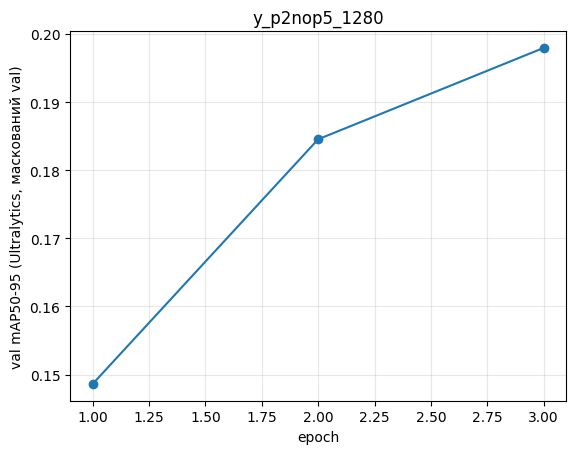

,exp,imgsz,batch,lr0,nq,nd,epochs,train_min,ms_per_frame,mAP,...,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor,box,cls
0,rt_nq500,960,6,0.0001,500.0,100.0,3,55.0,74,0.0624,...,0.0599,0.0287,0.2091,0.0604,0.0710,0.0350,0.0213,0.0135,NaN,NaN
1,rt_giou,960,6,0.0001,300.0,100.0,3,56.3,82,0.0877,...,0.1027,0.0403,0.2767,0.0771,0.0759,0.0970,0.0058,0.0261,NaN,NaN
2,y_1280_loss_nomask,1280,8,NaN,NaN,NaN,3,28.2,60,0.1854,...,0.2788,0.1732,0.4192,0.1745,0.1478,0.1664,0.0061,0.1173,10.0,1.0
3,y_p2_1280,1280,6,NaN,NaN,NaN,3,41.8,63,0.1835,...,0.2605,0.1427,0.3768,0.2236,0.0548,0.2192,0.0807,0.1098,10.0,1.0
4,y_p2nop5_1280,1280,6,NaN,NaN,NaN,3,40.3,93,0.1862,...,0.2494,0.2034,0.3815,0.1877,0.1156,0.2214,0.0179,0.1126,10.0,1.0


In [29]:
rc = pd.read_csv(WORK/"runs"/EXP/"results.csv"); rc.columns = [c.strip() for c in rc.columns]
rc.to_csv(WORK/f"curve_{EXP}.csv", index=False)
plt.plot(rc["epoch"], rc["metrics/mAP50-95(B)"], marker="o"); plt.xlabel("epoch"); plt.ylabel("val mAP50-95 (Ultralytics, маскований val)")
plt.title(EXP); plt.grid(alpha=.3); plt.show()
display(pd.read_csv(WORK/"results_all.csv").round(4))

### 4.5 Test-time augmentation (inference strategy, same weights)

In [ ]:
RUN_TTA = True
if RUN_TTA:
    p2, ms2 = predict_items(make_yolo_fn(BEST, IMGSZ, augment=True), ITEMS)
    o2, _ = eval_report(gt, p2, ITEMS)
    print({k: round(v, 4) for k, v in o2.items()}, f"| {ms2:.0f} мс/кадр")
    log_result(dict(exp=EXP + "_tta", **cfg, epochs=EPOCHS, ms_per_frame=round(ms2), **o2))

{'mAP': 0.2115, 'AP50': 0.4072, 'AP75': 0.1961, 'APs': 0.1077, 'APm': 0.198, 'APl': 0.3442, 'AP_person': 0.2666, 'AP_bicycle': 0.2006, 'AP_car': 0.4063, 'AP_van': 0.1959, 'AP_truck': 0.19, 'AP_tricycle': 0.1868, 'AP_bus': 0.1525, 'AP_motor': 0.0934} | 69 мс/кадр


### 4.6 Test predictions → `submission_<EXP>.csv`
Also stores the raw predictions (`test_preds_<EXP>.pkl`) for the ensemble in section 9.

In [ ]:
def check_submission(path):
    sub = pd.read_csv(path, keep_default_na=False)
    te = pd.read_csv(ROOT / "test_images.csv")
    assert set(sub.image_id) == set(te.image_id) and len(sub) == len(te), "image_id don't match"
    n = sub.PredictionString.map(lambda s: len(s.split()) // 6)
    assert (sub.PredictionString.map(lambda s: len(s.split()) % 6) == 0).all(), "not a multiple of 6 amount of tokens"
    print(f"OK: {len(sub)} rows, detections/frame: mean={n.mean():.1f} max={n.max()}, empty={int((n == 0).sum())}")

MAKE_SUBMISSION = True
if MAKE_SUBMISSION and not SMOKE:
    out = predict_test(fn)
    save_preds(out, f"test_preds_{EXP}.pkl")
    path = write_submission(out, WORK/f"submission_{EXP}.csv")
    check_submission(path)
    import shutil; shutil.copy(path, WORK/"submission.csv"); print("done:", path)

OK: 3811 рядків, детекцій/кадр: mean=265.6 max=300, порожніх=0
готово: /content/work/submission_y_final.csv


### 4.7 Backup to Google Drive
Run after every training run: copies `best_<EXP>.pt`, `last_<EXP>.pt`, predictions, curves and submissions to `hw2_out/` and merges `results_all.csv` there.

In [30]:
backup()

copied 37 files to /content/drive/MyDrive/hw2_out


## 5. Shared code for the torchvision detectors (Faster R-CNN, RetinaNet)
Dataset (reads the preprocessed frames and YOLO labels, horizontal-flip augmentation), SGD training loop (warm-up + cosine schedule, AMP, gradient clipping, per-epoch validation callback) and an inference wrapper. The same loop and budget are used for both detectors.

In [ ]:
import math, random, time
from pathlib import Path
import cv2, numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader, Dataset


cv2.setNumThreads(0)


class YoloDet(Dataset):
    def __init__(self, ds, split, label_offset=0, train=False, stride=1):
        self.lab_dir = Path(ds) / "labels" / split
        self.paths = sorted((Path(ds) / "images" / split).glob("*.jpg"))[::stride]
        self.off, self.train = label_offset, train

    def __len__(self):
        return len(self.paths)

    def read(self, i):
        p = self.paths[i]
        im = np.ascontiguousarray(cv2.imread(str(p))[:, :, ::-1])      # RGB
        h, w = im.shape[:2]
        a = np.array((self.lab_dir / f"{p.stem}.txt").read_text().split(), dtype=np.float32).reshape(-1, 5)
        c, cx, cy, bw, bh = a.T
        b = np.stack([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h], 1)
        keep = ((b[:, 2] - b[:, 0]) >= 1) & ((b[:, 3] - b[:, 1]) >= 1)
        return im, b[keep], c[keep].astype(np.int64)

    def __getitem__(self, i):
        im, b, c = self.read(i)
        if self.train and random.random() < 0.5:
            im = np.ascontiguousarray(im[:, ::-1]); w = im.shape[1]
            b = b.copy(); b[:, [0, 2]] = w - b[:, [2, 0]]
        x = torch.from_numpy(im).permute(2, 0, 1).float().div(255)
        return x, {"boxes": torch.from_numpy(b).float().reshape(-1, 4), "labels": torch.from_numpy(c + self.off)}


def collate(b):
    return tuple(zip(*b))


def class_weights(ds, n=8, power=0.5, lo=0.5, hi=3.0):
    cnt = np.zeros(n)
    for f in (Path(ds) / "labels" / "train").glob("*.txt"):
        for ln in f.read_text().splitlines():
            if ln:
                cnt[int(ln.split()[0])] += 1
    w = np.clip((np.median(cnt) / cnt) ** power, lo, hi)
    return torch.tensor([1.0] + list(w), dtype=torch.float32)


def train(model, train_ds, epochs, bs=4, lr=0.01, workers=4, device="cuda", warmup=300, clip=10.0,
          on_epoch_end=None, max_iters=None, log_every=100):
    loader = DataLoader(train_ds, batch_size=bs, shuffle=True, num_workers=workers, collate_fn=collate,
                        drop_last=True, persistent_workers=workers > 0)
    model.to(device).train()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=1e-4, nesterov=True)
    total = max_iters or epochs * len(loader)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda it: min(1.0, (it + 1) / warmup) * (0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(it, total) / total))))
    try: scaler = torch.amp.GradScaler("cuda")
    except Exception: scaler = torch.cuda.amp.GradScaler()
    hist, it, t0 = [], 0, time.time()
    for ep in range(epochs):
        model.train(); run, n = 0.0, 0
        for imgs, tgts in loader:
            imgs = [i.to(device, non_blocking=True) for i in imgs]
            tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
            with torch.autocast("cuda", dtype=torch.float16):
                loss = sum(model(imgs, tgts).values())
            opt.zero_grad(set_to_none=True)
            if torch.isfinite(loss):
                scaler.scale(loss).backward()
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, clip)
                scaler.step(opt); scaler.update()
                run += loss.item(); n += 1
            else:
                print("non-finite loss, step skipped")
            sched.step(); it += 1
            if it % log_every == 0:
                print(f"ep {ep + 1} it {it}/{total} loss {run / max(n, 1):.3f} lr {sched.get_last_lr()[0]:.5f} {time.time() - t0:.0f}s")
            if it >= total:
                break
        rec = dict(epoch=ep + 1, train_loss=run / max(n, 1), elapsed_s=round(time.time() - t0))
        if on_epoch_end:
            rec.update(on_epoch_end(ep + 1))
        hist.append(rec); print(rec)
        if it >= total:
            break
    return pd.DataFrame(hist)


def make_predict_fn(model, label_offset=0, device="cuda", half=True):
    model.to(device).eval()

    @torch.no_grad()
    def fn(path):
        im = np.ascontiguousarray(cv2.imread(str(path))[:, :, ::-1])
        x = torch.from_numpy(im).permute(2, 0, 1).float().div(255).to(device)
        with torch.autocast("cuda", enabled=half, dtype=torch.float16):
            o = model([x])[0]
        return o["boxes"].float().cpu().numpy(), o["scores"].float().cpu().numpy(), o["labels"].cpu().numpy() - label_offset
    return fn

## 6. Two-stage anchor-based detector — Faster R-CNN
**Model.** torchvision `fasterrcnn_resnet50_fpn_v2`, COCO-pretrained, new 9-way box predictor (background + 8 classes). Input 1280×720 (`min_size = 720`, `max_size = 1280`), SGD lr 0.01 (momentum 0.9, Nesterov, weight decay 1e-4), 300 warm-up iterations + cosine decay, batch 4, AMP, gradient clipping 10, horizontal flip, `EPOCHS` passes over the 8090 frames, seed 0.

**What each stage does.** Stage 1 (RPN) scores anchors on the FPN levels and keeps the top proposals; stage 2 (RoI head) pools features for every proposal, classifies it and refines the box. Section 6.5 measures the recall of the proposals — an upper bound for what stage 2 can reach.

**Experiments (one per run; set `EXP`).**

| preset | change | parameter investigated |
|---|---|---|
| `frcnn_base` | default anchors 32–512 | baseline |
| `frcnn_anch16` | anchors 16–256 (5th-percentile object ≈ 20 px, see EDA) | RPN anchor sizes |
| `frcnn_prop2k` | anchors 16–256 + 3000 / 2000 RPN proposals (train / test) | number of RPN proposals |
| `frcnn_roi_samp` (optional) | anchors 16–256 + RoI batch 256, 50 % positives | RoI sampling ratio |
| `frcnn_wce` (optional) | anchors 16–256 + class-weighted cross-entropy | loss modification |

In [ ]:
import gc, torch
for _n in ("model", "fn", "train_ds", "m", "BEST"): globals().pop(_n, None)
gc.collect(); torch.cuda.empty_cache()
print("GPU memory in use: %.2f GB" % (torch.cuda.memory_allocated() / 1e9))

### 6.1 Configuration
Set `EXP`, `EPOCHS`, `BS`, `SMOKE` here.

In [ ]:
import os, sys, time, json
import numpy as np, pandas as pd, cv2, torch, torch.nn.functional as F, matplotlib.pyplot as plt

DS = get_ds(); gt = load_val_gt(DS); ITEMS = val_items(gt)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU!")

EXP, EPOCHS, BS, SMOKE = "frcnn_base", 1, 4, False
MAX_ITERS = 30 if SMOKE else None
if SMOKE: ITEMS = ITEMS[::20]
A16 = (16, 32, 64, 128, 256)
PRESETS = {
    "frcnn_base":     {},
    "frcnn_anch16":   dict(anchor_sizes=A16),
    "frcnn_prop2k":   dict(anchor_sizes=A16, rpn_pre_nms_top_n_train=4000, rpn_post_nms_top_n_train=3000,
                           rpn_pre_nms_top_n_test=3000, rpn_post_nms_top_n_test=2000),
    "frcnn_roi_samp": dict(anchor_sizes=A16, box_batch_size_per_image=256, box_positive_fraction=0.5),
    "frcnn_wce":      dict(anchor_sizes=A16, cls_weights=True),
}
cfg = PRESETS[EXP]; print(EXP, cfg)

### 6.2 Model: pretrained Faster R-CNN, anchors / RPN / RoI settings from the preset, patched RoI loss (optional class weights)

In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
import torchvision.models.detection.roi_heads as RH

def build(cfg):
    kw = dict(min_size=720, max_size=1280, box_score_thresh=0.001, box_nms_thresh=0.5, box_detections_per_img=300)
    for k in ("rpn_pre_nms_top_n_train", "rpn_pre_nms_top_n_test", "rpn_post_nms_top_n_train",
              "rpn_post_nms_top_n_test", "box_batch_size_per_image", "box_positive_fraction"):
        if k in cfg: kw[k] = cfg[k]
    m = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT, **kw)
    if "anchor_sizes" in cfg:
        n = len(cfg["anchor_sizes"])
        m.rpn.anchor_generator = AnchorGenerator(tuple((s,) for s in cfg["anchor_sizes"]), ((0.5, 1.0, 2.0),) * n)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 9)   # background + 8 classes
    return m

def patch_roi_loss(cls_w=None, beta=1 / 9):
    def fastrcnn_loss(class_logits, box_regression, labels, regression_targets):
        labels = torch.cat(labels, 0); regression_targets = torch.cat(regression_targets, 0)
        w = cls_w.to(class_logits.device) if cls_w is not None else None
        cls_loss = F.cross_entropy(class_logits.float(), labels, weight=w)
        pos = torch.where(labels > 0)[0]; lp = labels[pos]
        N = class_logits.shape[0]
        box_regression = box_regression.float().reshape(N, box_regression.size(-1) // 4, 4)
        box_loss = F.smooth_l1_loss(box_regression[pos, lp], regression_targets[pos], beta=beta, reduction="sum") / labels.numel()
        return cls_loss, box_loss
    RH.fastrcnn_loss = fastrcnn_loss

torch.manual_seed(0)
cw = class_weights(DS) if cfg.get("cls_weights") else None
print("class weights:", None if cw is None else cw.numpy().round(2))
patch_roi_loss(cw)
model = build(cfg)

### 6.3 Training
After every epoch the model is validated on every 4th validation frame (learning-curve metric).

In [ ]:
train_ds = YoloDet(DS, "train", label_offset=1, train=True)
quick = ITEMS[::4]
def on_epoch(ep):
    p, _ = predict_items(make_predict_fn(model, label_offset=1), quick)
    r = coco_eval(gt, p, img_ids=[i for i, _, _ in quick]); model.train()
    return {"val_mAP": round(r["mAP"], 4), "val_AP50": round(r["AP50"], 4), "val_APs": round(r["APs"], 4)}

t0 = time.time()
hist = train(model, train_ds, epochs=EPOCHS, bs=BS, lr=0.01, on_epoch_end=on_epoch, max_iters=MAX_ITERS)
train_min = (time.time() - t0) / 60
hist.to_csv(WORK/f"curve_{EXP}.csv", index=False); torch.save(model.state_dict(), WORK/f"{EXP}.pth")
print(f"{train_min:.1f} m")

### 6.4 Evaluation: mAP, AP50, AP_small, inference speed, per class and per clip

In [ ]:
fn = make_predict_fn(model, label_offset=1)
preds, ms = predict_items(fn, ITEMS)
overall, per_clip = eval_report(gt, preds, ITEMS)
print({k: round(v, 4) for k, v in overall.items()}, f"| {ms:.0f} ms/frame")
display(per_clip)
json.dump(preds, open(WORK/f"val_preds_{EXP}.json", "w"))
log_result(dict(exp=EXP, epochs=EPOCHS, bs=BS, train_min=round(train_min, 1), ms_per_frame=round(ms), **overall))
display(pd.read_csv(WORK/"results_all.csv").round(4))

### 6.5 What the RPN contributes: proposal recall
Share of ground-truth objects covered (IoU ≥ 0.5 / 0.7) by the top-K proposals, for all and for small objects. The second stage can only classify and refine what the RPN proposes, so this recall bounds the achievable AP50.

In [ ]:
@torch.no_grad()
def rpn_recall(model, split="val", step=5, ks=(100, 300, 1000, 2000)):
    from torchvision.ops import box_iou
    ds_v = YoloDet(DS, split, label_offset=1); model.eval().cuda()
    hit = {(k, t, s): [0, 0] for k in ks for t in (0.5, 0.7) for s in ("all", "small")}
    for i in range(0, len(ds_v), step):
        x, t = ds_v[i]
        il, _ = model.transform([x.cuda()])
        with torch.autocast("cuda", dtype=torch.float16):
            props, _ = model.rpn(il, model.backbone(il.tensors))
        p = props[0].float(); g = t["boxes"].cuda() * (il.image_sizes[0][0] / x.shape[1])
        if len(g) == 0: continue
        size = ((g[:, 2] - g[:, 0]) * (g[:, 3] - g[:, 1])).sqrt()
        for k in ks:
            best = box_iou(g, p[:k]).max(1).values
            for th in (0.5, 0.7):
                ok = best >= th
                hit[(k, th, "all")][0] += ok.sum().item(); hit[(k, th, "all")][1] += len(g)
                sm = size < 32
                hit[(k, th, "small")][0] += ok[sm].sum().item(); hit[(k, th, "small")][1] += sm.sum().item()
    return pd.Series({f"top{k}_IoU{t}_{s}": v[0] / max(v[1], 1) for (k, t, s), v in hit.items()}).round(3)
print(rpn_recall(model))
print("For compare: AP50 of final model =", round(overall["AP50"], 3))

### 6.6 Failure-case analysis
Per-frame error taxonomy (score ≥ 0.3, IoU ≥ 0.5): TP / class confusion / false positive outside ignore regions / FN / small-object FN, and the three frames with the most small-object misses, false positives and class confusions.

In [ ]:
fa = analyze_failures(gt, preds, ITEMS, thr=0.3)
print("Sum on val:", fa[["n_gt", "TP", "CONF", "FP", "FN", "FN_small"]].sum().to_dict())
cases = {"(FN_small)": fa.loc[fa.FN_small.idxmax()],
         "(FP)":         fa.loc[fa.FP.idxmax()],
         "(CONF)":       fa.loc[fa.CONF.idxmax()]}
paths = {i: p for i, p, _ in ITEMS}
fig, axs = plt.subplots(1, 3, figsize=(24, 5))
for ax, (title, r) in zip(axs, cases.items()):
    ax.imshow(draw_case(gt, preds, int(r.image_id), paths[int(r.image_id)])); ax.axis("off")
    ax.set_title(f"{title}\n{r.video}  GT={r.n_gt} TP={r.TP} FP={r.FP} FN={r.FN} CONF={r.CONF}")
plt.tight_layout(); plt.savefig(WORK/f"failures_{EXP}.png", dpi=80); plt.show()

### 6.7 Test predictions (optional, off by default)

In [ ]:
MAKE_TEST = False
if MAKE_TEST and not SMOKE:
    out = predict_test(fn); save_preds(out, f"test_preds_{EXP}.pkl")
    path = write_submission(out, WORK/f"submission_{EXP}.csv"); check_submission(path)

## 7. One-stage anchor-based detector — RetinaNet
**Model.** torchvision `retinanet_resnet50_fpn_v2` (COCO-pretrained backbone, FPN and regression head; new 8-class classification head). Anchors: 3 scales × 3 aspect ratios {0.5, 1, 2} on each FPN level; the ratios follow the 5–95 % range of object aspect ratios in the EDA (0.39–2.45), the sizes follow the object-size distribution. Same input size, optimiser, budget and protocol as Faster R-CNN.

**Without a proposal stage** all ≈ 170 k anchors per frame are classified directly. Two issues follow: an extreme background / object imbalance (addressed by focal loss) and small objects that no anchor matches well (addressed by smaller anchors and lower IoU thresholds). Section 7.5 quantifies both on the validation set.

**Experiments (one per run; set `EXP`).**

| preset | change | parameter investigated |
|---|---|---|
| `retina_base` | default anchors 32–512, IoU fg/bg 0.5/0.4, focal α = 0.25, γ = 2, GIoU box loss (torchvision v2 default) | baseline |
| `retina_anch16` | anchors 16–256 | anchor scales (grounded in the EDA) |
| `retina_thr` (optional) | + IoU fg/bg 0.4/0.3 | assignment thresholds |
| `retina_focal` | + focal α = 0.5, γ = 1.5 | focal-loss parameters |
| `retina_l1` | + classic L1 box loss instead of the default GIoU | loss modification |

In [ ]:
import gc, torch
for _n in ("model", "fn", "train_ds", "m", "BEST"): globals().pop(_n, None)
gc.collect(); torch.cuda.empty_cache()
print("GPU memory in use: %.2f GB" % (torch.cuda.memory_allocated() / 1e9))

### 7.1 Configuration
Set `EXP`, `EPOCHS`, `BS`, `SMOKE` here.

In [ ]:
import os, sys, time, json
import numpy as np, pandas as pd, cv2, torch, matplotlib.pyplot as plt
from functools import partial
from torch import nn

DS = get_ds(); gt = load_val_gt(DS); ITEMS = val_items(gt)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU!")

EXP, EPOCHS, BS, SMOKE = "retina_base", 1, 4, False
MAX_ITERS = 30 if SMOKE else None
if SMOKE: ITEMS = ITEMS[::20]
A16 = (16, 32, 64, 128, 256)
PRESETS = {
    "retina_base":   {},
    "retina_anch16": dict(base_sizes=A16),
    "retina_thr":    dict(base_sizes=A16, fg_iou=0.4, bg_iou=0.3),
    "retina_focal":  dict(base_sizes=A16, alpha=0.5, gamma=1.5),
    "retina_l1":     dict(base_sizes=A16, box_loss="l1"),
}
cfg = PRESETS[EXP]; print(EXP, cfg)

### 7.2 Model: anchors from the object-size analysis, assignment thresholds, focal-loss parameters, box-loss type

In [ ]:
import math
from torchvision.models.detection import retinanet_resnet50_fpn_v2, RetinaNet_ResNet50_FPN_V2_Weights
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
import torchvision.models.detection.retinanet as RN
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection import _utils as det_utils
from torchvision.ops import sigmoid_focal_loss

def build(cfg):
    m = retinanet_resnet50_fpn_v2(weights=RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT, min_size=720, max_size=1280,
                                  score_thresh=0.001, nms_thresh=0.5, detections_per_img=300, topk_candidates=2000)
    ch = m.head.classification_head; na = ch.num_anchors
    ch.cls_logits = nn.Conv2d(256, na * 8, kernel_size=3, stride=1, padding=1)
    nn.init.normal_(ch.cls_logits.weight, std=0.01)
    nn.init.constant_(ch.cls_logits.bias, -math.log((1 - 0.01) / 0.01))
    ch.num_classes = 8
    sizes = cfg.get("base_sizes", (32, 64, 128, 256, 512))
    m.anchor_generator = AnchorGenerator(tuple((s, int(s * 2 ** (1 / 3)), int(s * 2 ** (2 / 3))) for s in sizes), ((0.5, 1.0, 2.0),) * len(sizes))
    m.proposal_matcher = det_utils.Matcher(cfg.get("fg_iou", 0.5), cfg.get("bg_iou", 0.4), allow_low_quality_matches=True)
    if "box_loss" in cfg: m.head.regression_head._loss_type = cfg["box_loss"]
    return m

RN.sigmoid_focal_loss = partial(sigmoid_focal_loss, alpha=cfg.get("alpha", 0.25), gamma=cfg.get("gamma", 2.0))
torch.manual_seed(0)
model = build(cfg)
print("box loss:", model.head.regression_head._loss_type, "| anchors per location:", model.head.classification_head.num_anchors)

### 7.3 Training (same loop and budget as Faster R-CNN)

In [ ]:
train_ds = YoloDet(DS, "train", label_offset=0, train=True)
quick = ITEMS[::4]
def on_epoch(ep):
    p, _ = predict_items(make_predict_fn(model, label_offset=0), quick)
    r = coco_eval(gt, p, img_ids=[i for i, _, _ in quick]); model.train()
    return {"val_mAP": round(r["mAP"], 4), "val_AP50": round(r["AP50"], 4), "val_APs": round(r["APs"], 4)}

t0 = time.time()
hist = train(model, train_ds, epochs=EPOCHS, bs=BS, lr=0.01, on_epoch_end=on_epoch, max_iters=MAX_ITERS)
train_min = (time.time() - t0) / 60
hist.to_csv(WORK/f"curve_{EXP}.csv", index=False); torch.save(model.state_dict(), WORK/f"{EXP}.pth")
print(f"{train_min:.1f} m")

### 7.4 Evaluation: mAP, AP50, AP_small, inference speed, per class and per clip

In [ ]:
fn = make_predict_fn(model, label_offset=0)
preds, ms = predict_items(fn, ITEMS)
overall, per_clip = eval_report(gt, preds, ITEMS)
print({k: round(v, 4) for k, v in overall.items()}, f"| {ms:.0f} ms/frame")
display(per_clip)
json.dump(preds, open(WORK/f"val_preds_{EXP}.json", "w"))
log_result(dict(exp=EXP, epochs=EPOCHS, bs=BS, train_min=round(train_min, 1), ms_per_frame=round(ms), **overall))
display(pd.read_csv(WORK/"results_all.csv").round(4))

### 7.5 What changes without a proposal stage: anchor coverage and imbalance
Number of positive anchors versus all anchors (imbalance), and the share of ground-truth objects — overall and small ones — that have no anchor above the foreground IoU threshold.

In [ ]:
@torch.no_grad()
def anchor_coverage(model, split="val", step=10):
    from torchvision.ops import box_iou
    ds_v = YoloDet(DS, split, label_offset=0); model.eval().cuda()
    fg, bg = model.proposal_matcher.high_threshold, model.proposal_matcher.low_threshold
    rows = []
    for i in range(0, len(ds_v), step):
        x, t = ds_v[i]
        il, _ = model.transform([x.cuda()])
        feats = list(model.backbone(il.tensors).values())
        a = model.anchor_generator(il, feats)[0]
        g = t["boxes"].cuda() * (il.image_sizes[0][0] / x.shape[1])
        if len(g) == 0: continue
        iou = box_iou(g, a); best = iou.max(1).values
        size = ((g[:, 2] - g[:, 0]) * (g[:, 3] - g[:, 1])).sqrt()
        rows.append(dict(anchors=len(a), pos_anchors=(iou.max(0).values >= fg).sum().item(),
                         gt=len(g), gt_no_pos=(best < fg).sum().item(), small_gt=(size < 32).sum().item(),
                         small_no_pos=((best < fg) & (size < 32)).sum().item()))
    d = pd.DataFrame(rows).sum()
    print(f"anchors/frame: {d['anchors'] / len(rows):.0f}; positive anchors/frame: {d['pos_anchors'] / len(rows):.0f} "
          f"(share {d['pos_anchors'] / d['anchors'] * 100:.2f}% -> background:object imbalance ~ {d['anchors'] / max(d['pos_anchors'], 1):.0f}:1)")
    print(f"GT objects without any anchor at IoU >= {fg}: {d['gt_no_pos'] / d['gt'] * 100:.1f}% overall, "
          f"{d['small_no_pos'] / max(d['small_gt'], 1) * 100:.1f}% among small objects (< 32 px at network input)")
anchor_coverage(model)

### 7.6 Test predictions (optional, off by default)

In [ ]:
MAKE_TEST = False
if MAKE_TEST and not SMOKE:
    out = predict_test(fn); save_preds(out, f"test_preds_{EXP}.pkl")
    path = write_submission(out, WORK/f"submission_{EXP}.csv"); check_submission(path)

## 8. Query-based detector — RT-DETR
**Model.** Ultralytics `rtdetr-l` (COCO-pretrained; HGNetV2 backbone, hybrid encoder, 6-layer decoder, 300 object queries). The budget equals the YOLO baseline `y_base_960`: same data, 960 px, same number of epochs; AdamW, lr 1e-4, seed 0.

**Bipartite matching.** In training every ground-truth box is assigned to exactly one query by Hungarian matching (cost = classification + L1 + GIoU); all other queries are trained to predict “no object”. Duplicate predictions are therefore penalised by the loss itself, and no NMS is needed at inference (checked in 8.6). One-to-one assignment gives sparser supervision than the many-to-one assignment of CNN detectors and usually converges more slowly; denoising queries are added to speed it up.

**Experiments (one per run; set `EXP`).**

| preset | change | parameter investigated |
|---|---|---|
| `rt_base` | 300 queries, 100 denoising queries, default weights | baseline |
| `rt_nq500` | 500 queries | number of queries vs. scene density (up to 180 objects per frame) |
| `rt_nodn` (optional) | denoising queries off | denoising loss |
| `rt_giou` | GIoU weight × 2 in the matching cost and in the loss | matching cost weights / loss |

In [ ]:
import gc, torch
for _n in ("model", "fn", "train_ds", "m", "BEST"): globals().pop(_n, None)
gc.collect(); torch.cuda.empty_cache()
print("GPU memory in use: %.2f GB" % (torch.cuda.memory_allocated() / 1e9))

### 8.1 Configuration
Set `EXP`, `EPOCHS`, `SMOKE` here. Keep `EPOCHS` equal to the YOLO baseline (3).

In [ ]:
import os, sys, time, json
os.environ["WANDB_DISABLED"] = "true"
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from collections import defaultdict
from ultralytics import RTDETR, settings
settings.update({"wandb": False})

DS = get_ds(); YAML = make_yaml(DS); gt = load_val_gt(DS); ITEMS = val_items(gt)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU!")

EXP, EPOCHS, SMOKE = "rt_giou", 3, False
if SMOKE: ITEMS = ITEMS[::20]
BASE = dict(imgsz=960, batch=6, lr0=1e-4)
PRESETS = {
    "rt_base":  dict(BASE),
    "rt_nq500": dict(BASE, nq=500),
    "rt_nodn":  dict(BASE, nd=0),
    "rt_giou":  dict(BASE, cost_gain={"giou": 4}, loss_gain={"giou": 4}),
}
cfg = dict(PRESETS[EXP]); print(EXP, cfg)

GPU: Tesla T4
rt_giou {'imgsz': 960, 'batch': 6, 'lr0': 0.0001, 'cost_gain': {'giou': 4}, 'loss_gain': {'giou': 4}}


### 8.2 Patches for the experiments
The trainer rebuilds the model, so the number of queries, denoising groups and the loss / matching weights are patched into the Ultralytics classes. The printed `[patch]` lines confirm that the settings were applied.

In [ ]:
from ultralytics.nn.modules import head
from ultralytics.nn import tasks

NQ, ND = cfg.pop("nq", None), cfg.pop("nd", None)
LOSS_GAIN, COST_GAIN = cfg.pop("loss_gain", None), cfg.pop("cost_gain", None)

if not hasattr(head.RTDETRDecoder, "_orig_init"):
    head.RTDETRDecoder._orig_init = head.RTDETRDecoder.__init__
if not hasattr(tasks.RTDETRDetectionModel, "_orig_crit") and hasattr(tasks.RTDETRDetectionModel, "init_criterion"):
    tasks.RTDETRDetectionModel._orig_crit = tasks.RTDETRDetectionModel.init_criterion

def _init(self, *a, **k):
    head.RTDETRDecoder._orig_init(self, *a, **k)
    if NQ is not None: self.num_queries = NQ
    if ND is not None: self.num_denoising = ND
    print(f"[patch] decoder: num_queries={self.num_queries}, num_denoising={self.num_denoising}")

def _crit(self):
    c = tasks.RTDETRDetectionModel._orig_crit(self)
    try:
        if LOSS_GAIN: c.loss_gain.update(LOSS_GAIN)
        if COST_GAIN: c.matcher.cost_gain.update(COST_GAIN)
        print("[patch] loss_gain:", c.loss_gain, "| matcher cost_gain:", c.matcher.cost_gain)
    except AttributeError as e:
        print("[patch] loss/matching weights NOT applied (different ultralytics version):", e)
    return c

head.RTDETRDecoder.__init__ = _init
if hasattr(tasks.RTDETRDetectionModel, "_orig_crit"):
    tasks.RTDETRDetectionModel.init_criterion = _crit
else:
    print("[patch] init_criterion not found: loss/matching weights stay at their defaults")


### 8.3 Training

In [ ]:
model = RTDETR("rtdetr-l.pt")
t0 = time.time()
model.train(data=str(YAML), epochs=1 if SMOKE else EPOCHS, fraction=0.03 if SMOKE else 1.0, workers=4, device=0, seed=0,
            optimizer="AdamW", project=str(WORK/"runs"), name=EXP, exist_ok=True, plots=False, amp=True, **cfg)
train_min = (time.time() - t0) / 60
BEST = Path(model.trainer.best); print("best:", BEST, f"| {train_min:.1f} min")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/ds_s3_mask.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rt_giou, nbs=64, nms=None, opset=None, optimize=False, opt

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/3      9.89G        2.8     0.4313     0.2673        116        960: 100% ━━━━━━━━━━━━ 1349/1349 1.3it/s 16:59
[patch] loss_gain: {'class': 1, 'bbox': 5, 'giou': 4} | matcher cost_gain: {'class': 2, 'bbox': 5, 'giou': 4}
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 48/48 2.0it/s 24.2s
                   all        571      22906       0.57      0.198     0.0864     0.0442

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
        2/3       9.3G      1.473     0.7471    0.08966        251        960: 0% ──────────── 0/1349  0.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        2/3      9.31G      1.788     0.6661     0.1044         44        960: 100% ━━━━━━━━━━━━ 1349/1349 1.3it/s 17:02
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 48/48 2.0it/s 23.5s
                   all        571      22906       0.11      0.378      0.113     0.0657

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
        3/3      9.48G      1.652     0.6628     0.1099        243        960: 0% ──────────── 0/1349  0.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        3/3      9.48G      1.283     0.7755     0.0768         66        960: 100% ━━━━━━━━━━━━ 1349/1349 1.3it/s 17:07
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 48/48 1.9it/s 24.9s
                   all        571      22906      0.162      0.326      0.134      0.076

3 epochs completed in 0.927 hours.
Optimizer stripped from /content/work/runs/rt_giou/weights/last.pt, 66.3MB
Optimizer stripped from /content/work/runs/rt_giou/weights/best.pt, 66.3MB

Validating /content/work/runs/rt_giou/weights/best.pt...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 48/48 2.1it/s 22.8s
                   all        571      22906      0.166      0.322      0.135     0.0762
                person       

### 8.4 Evaluation: mAP, AP50, AP_small, inference speed, per class and per clip

In [ ]:
def make_rtdetr_fn(weights, imgsz, conf=0.001, max_det=300):
    m = RTDETR(str(weights))
    def fn(path):
        r = m.predict(str(path), imgsz=imgsz, conf=conf, max_det=max_det, half=True, verbose=False, device=0)[0]
        b = r.boxes
        return b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)
    return fn

fn = make_rtdetr_fn(BEST, cfg["imgsz"])
preds, ms = predict_items(fn, ITEMS)
overall, per_clip = eval_report(gt, preds, ITEMS)
print({k: round(v, 4) for k, v in overall.items()}, f"| {ms:.0f} ms/frame")
display(per_clip)
json.dump(preds, open(WORK/f"val_preds_{EXP}.json", "w"))
log_result(dict(exp=EXP, **cfg, nq=NQ or 300, nd=ND if ND is not None else 100, epochs=EPOCHS,
                train_min=round(train_min, 1), ms_per_frame=round(ms), **overall))
display(pd.read_csv(WORK/"results_all.csv").round(4))

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,clip,frames,obj_per_frame,med_size,mAP,AP50,APs
0,uav0000086_00000_v,93,49.667,39.912,0.048,0.109,0.094
1,uav0000117_02622_v,70,49.429,64.888,0.167,0.305,0.016
2,uav0000137_00458_v,47,103.362,73.294,0.151,0.265,0.000
3,uav0000182_00000_v,73,48.685,32.404,0.083,0.165,0.043
4,uav0000268_05773_v,196,13.872,48.280,0.020,0.034,0.009
5,uav0000305_00000_v,37,34.865,76.980,0.102,0.140,0.008
6,uav0000339_00001_v,55,43.745,48.672,0.106,0.176,0.023


,exp,imgsz,batch,lr0,nq,nd,epochs,train_min,ms_per_frame,mAP,...,APm,APl,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
0,rt_nq500,960,6,0.0001,500,100,3,55.0,74,0.0624,...,0.0503,0.1488,0.0599,0.0287,0.2091,0.0604,0.0710,0.035,0.0213,0.0135
1,rt_giou,960,6,0.0001,300,100,3,56.3,82,0.0877,...,0.0792,0.1835,0.1027,0.0403,0.2767,0.0771,0.0759,0.097,0.0058,0.0261


### 8.5 Validation mAP over epochs: RT-DETR vs. YOLO under the same budget
If RT-DETR has not converged within the budget, this is visible in the curve.

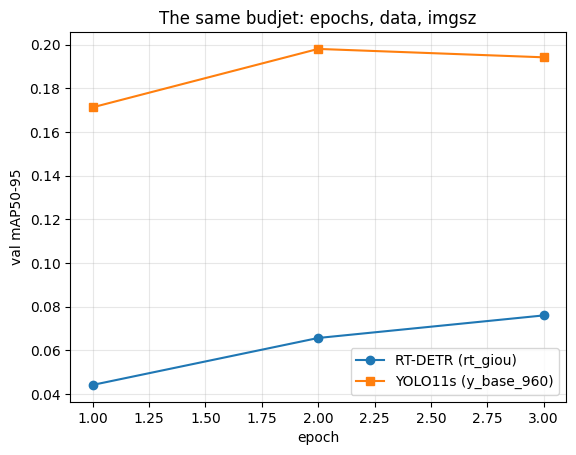

In [ ]:
YOLO_CURVE = next((p for p in [WORK / "curve_y_base_960.csv", Path("/content/drive/MyDrive/hw2_out/curve_y_base_960.csv")] if p.exists()), WORK / "curve_y_base_960.csv")
rc = pd.read_csv(WORK/"runs"/EXP/"results.csv"); rc.columns = [c.strip() for c in rc.columns]
rc.to_csv(WORK/f"curve_{EXP}.csv", index=False)
plt.plot(rc["epoch"], rc["metrics/mAP50-95(B)"], marker="o", label=f"RT-DETR ({EXP})")
if Path(YOLO_CURVE).exists():
    yc = pd.read_csv(YOLO_CURVE); plt.plot(yc["epoch"], yc["metrics/mAP50-95(B)"], marker="s", label="YOLO11s (y_base_960)")
else: print("YOLO CSV not found:", YOLO_CURVE)
plt.xlabel("epoch"); plt.ylabel("val mAP50-95"); plt.legend(); plt.grid(alpha=.3); plt.title("The same budjet: epochs, data, imgsz")
plt.savefig(WORK/"curve_rtdetr_vs_yolo.png", dpi=100); plt.show()

### 8.6 Bipartite matching and NMS
We apply class-wise NMS to the RT-DETR predictions and compare. If the one-to-one training works, NMS removes few boxes and changes the metric very little.

In [ ]:
import torchvision
def apply_nms(preds, iou=0.7):
    by = defaultdict(list)
    for i, p in enumerate(preds): by[p["image_id"]].append(i)
    keep_all = []
    for iid, idx in by.items():
        b = torch.tensor([[preds[i]["bbox"][0], preds[i]["bbox"][1], preds[i]["bbox"][0] + preds[i]["bbox"][2],
                           preds[i]["bbox"][1] + preds[i]["bbox"][3]] for i in idx])
        s = torch.tensor([preds[i]["score"] for i in idx]); c = torch.tensor([preds[i]["category_id"] for i in idx])
        keep_all += [idx[j] for j in torchvision.ops.batched_nms(b, s, c, iou).tolist()]
    return [preds[i] for i in keep_all]

p_nms = apply_nms(preds)
r0, r1 = coco_eval(gt, preds), coco_eval(gt, p_nms)
print(f"without NMS: mAP={r0['mAP']:.4f} AP50={r0['AP50']:.4f} ({len(preds)} boxes)")
print(f"with NMS:   mAP={r1['mAP']:.4f} AP50={r1['AP50']:.4f} ({len(p_nms)} boxes, deleted {len(preds) - len(p_nms)})")

without NMS: mAP=0.0877 AP50=0.1579 (171300 boxes)
with NMS:   mAP=0.1451 AP50=0.2872 (87636 boxes, deleted 83664)


### 8.7 Dense scenes and small objects
Per-clip mAP against the number of objects per frame.

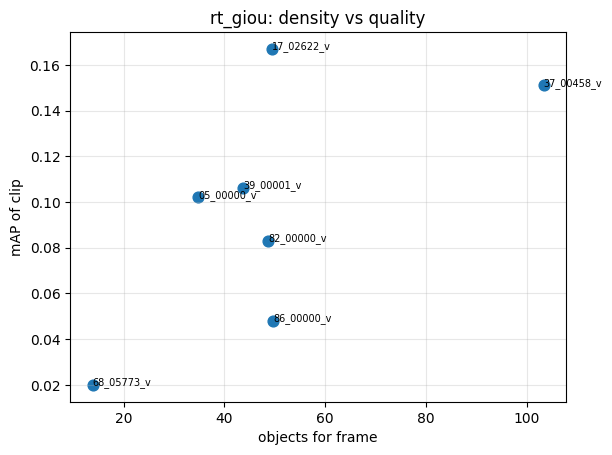

AP small/medium/large: 0.033 0.079 0.183


In [ ]:
plt.scatter(per_clip["obj_per_frame"], per_clip["mAP"], s=60)
for _, r in per_clip.iterrows(): plt.annotate(r["clip"][-10:], (r["obj_per_frame"], r["mAP"]), fontsize=7)
plt.xlabel("objects for frame"); plt.ylabel("mAP of clip"); plt.grid(alpha=.3); plt.title(f"{EXP}: density vs quality")
plt.savefig(WORK/f"density_{EXP}.png", dpi=100); plt.show()
print("AP small/medium/large:", round(overall["APs"], 3), round(overall["APm"], 3), round(overall["APl"], 3))

### 8.8 Test predictions (optional, off by default)

In [ ]:
MAKE_TEST = False
if MAKE_TEST and not SMOKE:
    out = predict_test(fn); save_preds(out, f"test_preds_{EXP}.pkl")
    path = write_submission(out, WORK/f"submission_{EXP}.csv"); check_submission(path)

## 9. Your pipeline — final solution, inference strategies, ensemble, comparison of all models
**Rubric:** Your Pipeline (1.25 pts). Everything here runs on **already trained YOLO weights** (no new training) and on **one and the same validation set** (571 val frames, pycocotools with `iscrowd`).

**The effect of the three factors is separated:**
| what changes | where | how |
|---|---|---|
| **Model** (resolution, loss weights, training length) | section 4 (YOLO runs), table in 9.5 | `y_base_960` → `y_1280` → `y_1280_loss` → `y_final` |
| **Inference** (NMS, TTA, scale, ensemble) | sections 9.2–9.3 | same `y_final` weights, only the way of producing predictions changes |
| **Data** (ignore-region masking) | section 9.5 | pair `y_1280_loss` ↔ `y_1280_loss_nomask` (identical settings, 3 epochs) |

**Before running:** Colab with GPU, Drive mounted, data unzipped, weights `best_<exp>.pt` / `last_<exp>.pt` copied to Drive (`CKPT` folder).

In [ ]:
!pip install -q ensemble-boxes

### 9.1 Configuration: weights and validation set

In [ ]:
import os, sys, json, time, logging, importlib.metadata as imd
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
logging.getLogger("ultralytics").setLevel(logging.ERROR)
import warnings; warnings.filterwarnings("ignore", module="ensemble_boxes")

CKPT = Path(os.environ.get("CKPT_DIR", "/content/drive/MyDrive/hw2_out"))
MODEL_CFG = {
    "y_final":     dict(w=CKPT / "best_y_final.pt",     imgsz=1280),
    "y_final_last": dict(w=CKPT / "last_y_final.pt",    imgsz=1280),
    "y_1280_loss": dict(w=CKPT / "best_y_1280_loss.pt", imgsz=1280),
    "y_1280":      dict(w=CKPT / "best_y_1280.pt",      imgsz=1280),
    "y_base_960":  dict(w=CKPT / "best_y_base_960.pt",  imgsz=960),
}
MODEL_CFG = {k: v for k, v in MODEL_CFG.items() if v["w"].exists()}
print("available weights:", list(MODEL_CFG)); assert "y_final" in MODEL_CFG, "best_y_final.pt is required in CKPT"

def make_val_gt(step=5, name="val_only"):
    """Same val subsample as in data preparation (every 5th frame of a clip); JSON only, no images."""
    d = json.load(open(ROOT / "val" / "annotations_coco.json", encoding="utf-8"))
    imgs = pd.DataFrame(d["images"]).rename(columns={"id": "image_id"})
    imgs["pos"] = imgs.groupby("video").frame_id.rank(method="first").astype(int) - 1
    keep = set(imgs[imgs.pos % step == 0].image_id)
    out = WORK / name; out.mkdir(exist_ok=True)
    json.dump({"images": [i for i in d["images"] if i["id"] in keep],
               "annotations": [a for a in d["annotations"] if a["image_id"] in keep],
               "categories": d["categories"]}, open(out / "val_subset_coco.json", "w"))
    return out

try: DS = find_ds("ds_s3_mask")
except FileNotFoundError: DS = make_val_gt()
gt = load_val_gt(DS); ITEMS = val_items(gt); VAL_PATHS = [p for _, p, _ in ITEMS]
print("val frames:", len(ITEMS), "(expected 571 for step=5)")
te = pd.read_csv(ROOT / "test_images.csv"); TEST_PATHS = [ROOT / f for f in te.file_name]; print("test frames:", len(TEST_PATHS))

available weights: ['y_final', 'y_final_last', 'y_base_960']
val frames: 571 (expected 571 for step=5)
test frames: 3811


### 9.2 Inference and ensemble: helper functions
- `get_model_preds` — predictions of one model on a set of frames; cached on disk (`pred_*.pkl`) so nothing is computed twice after a Colab crash.
- `fuse` — Weighted Boxes Fusion (WBF) of the predictions of several models (boxes are normalised by the frame size).
- One variant is described by: `models`, `weights`, `nms_iou`, `tta`, `scale` (inference resolution multiplier), `fuse_iou`.

In [ ]:
MEMO = {}

def img_size(p):
    with Image.open(p) as im: return im.size

def yolo_fn(weights, imgsz, conf=0.001, iou=0.6, max_det=300, augment=False):
    m = YOLO(str(weights))
    def fn(path):
        r = m.predict(str(path), imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, half=True,
                      augment=augment, verbose=False, device=0)[0]
        b = r.boxes
        return b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)
    return fn

def get_model_preds(split, paths, model, imgsz, iou=0.6, tta=False):
    key = f"{split}_{model}_{imgsz}_{iou}_{int(tta)}"
    f = WORK / f"pred_{key}.pkl"
    if key in MEMO: return MEMO[key]
    if f.exists():
        MEMO[key] = pickle.load(open(f, "rb")); return MEMO[key]
    fn = yolo_fn(MODEL_CFG[model]["w"], imgsz, iou=iou, augment=tta)
    t = time.time(); out = {str(p): fn(p) for p in paths}; ms = (time.time() - t) / len(paths) * 1000
    MEMO[key] = (out, ms); pickle.dump(MEMO[key], open(f, "wb")); return MEMO[key]

def fuse(outs, size, weights=None, iou_thr=0.6, skip=0.005, max_det=500):
    w, h = size; norm = np.array([w, h, w, h], dtype=float)
    bl = [np.clip(b / norm, 0, 1) if len(b) else np.zeros((0, 4)) for b, _, _ in outs]
    sl = [np.asarray(s, float) for _, s, _ in outs]; ll = [np.asarray(l, float) for _, _, l in outs]
    b, s, l = weighted_boxes_fusion(bl, sl, ll, weights=weights, iou_thr=iou_thr, skip_box_thr=skip)
    k = np.argsort(-s)[:max_det]
    return b[k] * norm, s[k], l[k].astype(int)

def predict_cfg(cfg, split, paths):
    scale = cfg.get("scale", 1.0)
    runs = [get_model_preds(split, paths, m, int(round(MODEL_CFG[m]["imgsz"] * scale / 32) * 32),
                            cfg.get("nms_iou", 0.6), cfg.get("tta", False)) for m in cfg["models"]]
    ms = sum(r[1] for r in runs)
    if len(runs) == 1: return runs[0][0], ms
    return {str(p): fuse([r[0][str(p)] for r in runs], img_size(p), cfg.get("weights"), cfg.get("fuse_iou", 0.6)) for p in paths}, ms

VAL_PREDS, ROWS = {}, []
def evaluate_cfg(cfg):
    cache, ms = predict_cfg(cfg, "val", VAL_PATHS)
    preds, _ = predict_items(lambda p: cache[str(p)], ITEMS)
    r = coco_eval(gt, preds); VAL_PREDS[cfg["name"]] = preds
    row = dict(exp=cfg["name"], **{k: round(r[k], 4) for k in ["mAP", "AP50", "AP75", "APs", "APm", "APl"]}, ms_per_frame=round(ms))
    ROWS.append(row); print(row); return row

### 9.3 Inference experiments (`y_final` weights) and ensembles
Reference point: `y_final` with standard inference (NMS IoU 0.6, `imgsz` as in training). Then **only** the way of inference changes.
Ensembles use WBF with model weights; `fuse_iou` is the box-merging threshold. Each variant takes ~1-5 min.

In [ ]:
A = dict(models=["y_final"])
EXPS = [
    dict(name="y_final | baseline", **A),
    dict(name="y_final | NMS 0.5", nms_iou=0.5, **A),
    dict(name="y_final | NMS 0.7", nms_iou=0.7, **A),
    dict(name="y_final | scale x1.2 (1536)", scale=1.2, **A),
    dict(name="y_final | TTA", tta=True, **A),
]
ENS = [("y_final", "y_final_last"), ("y_final", "y_1280_loss"), ("y_final", "y_final_last", "y_1280_loss"), ("y_final", "y_1280_loss", "y_1280")]
for combo in ENS:
    for fi in (0.55, 0.7):
        EXPS.append(dict(name=f"WBF {len(combo)} models | fuse {fi}", models=list(combo), weights=[2] + [1] * (len(combo) - 1), fuse_iou=fi))
EXPS.append(dict(name="WBF y_final+last | TTA", models=["y_final", "y_final_last"], weights=[1, 1], tta=True, fuse_iou=0.55))
EXPS = [e for e in EXPS if all(m in MODEL_CFG for m in e["models"])]
for e in EXPS: evaluate_cfg(e)
TABLE = pd.DataFrame(ROWS); display(TABLE.sort_values("mAP", ascending=False))

{'exp': 'y_final | baseline', 'mAP': 0.2011, 'AP50': 0.3909, 'AP75': 0.1816, 'APs': 0.1038, 'APm': 0.1933, 'APl': 0.3204, 'ms_per_frame': 88}
{'exp': 'y_final | NMS 0.5', 'mAP': 0.2007, 'AP50': 0.3915, 'AP75': 0.181, 'APs': 0.1033, 'APm': 0.1929, 'APl': 0.3197, 'ms_per_frame': 47}
{'exp': 'y_final | NMS 0.7', 'mAP': 0.201, 'AP50': 0.3867, 'AP75': 0.183, 'APs': 0.1047, 'APm': 0.1932, 'APl': 0.3205, 'ms_per_frame': 47}
{'exp': 'y_final | scale x1.2 (1536)', 'mAP': 0.201, 'AP50': 0.3949, 'AP75': 0.1773, 'APs': 0.1005, 'APm': 0.1973, 'APl': 0.3077, 'ms_per_frame': 55}
{'exp': 'y_final | TTA', 'mAP': 0.2115, 'AP50': 0.4072, 'AP75': 0.1961, 'APs': 0.1077, 'APm': 0.198, 'APl': 0.3442, 'ms_per_frame': 77}
{'exp': 'WBF 2 models | fuse 0.55', 'mAP': 0.2067, 'AP50': 0.4017, 'AP75': 0.1868, 'APs': 0.1111, 'APm': 0.2011, 'APl': 0.322, 'ms_per_frame': 139}
{'exp': 'WBF 2 models | fuse 0.7', 'mAP': 0.2105, 'AP50': 0.4063, 'AP75': 0.1904, 'APs': 0.1154, 'APm': 0.2056, 'APl': 0.3269, 'ms_per_frame': 13

,exp,mAP,AP50,AP75,APs,APm,APl,ms_per_frame
7,WBF y_final+last | TTA,0.2140,0.4141,0.1940,0.1112,0.2021,0.3440,157
4,y_final | TTA,0.2115,0.4072,0.1961,0.1077,0.1980,0.3442,77
6,WBF 2 models | fuse 0.7,0.2105,0.4063,0.1904,0.1154,0.2056,0.3269,139
5,WBF 2 models | fuse 0.55,0.2067,0.4017,0.1868,0.1111,0.2011,0.3220,139
0,y_final | baseline,0.2011,0.3909,0.1816,0.1038,0.1933,0.3204,88
2,y_final | NMS 0.7,0.2010,0.3867,0.1830,0.1047,0.1932,0.3205,47
3,y_final | scale x1.2 (1536),0.2010,0.3949,0.1773,0.1005,0.1973,0.3077,55
1,y_final | NMS 0.5,0.2007,0.3915,0.1810,0.1033,0.1929,0.3197,47


### 9.4 Does the improvement generalise? Per-clip mAP: best variant vs. baseline

In [ ]:
best = TABLE.sort_values("mAP").iloc[-1]; BEST_CFG = next(e for e in EXPS if e["name"] == best.exp)
print("best by val mAP:", best.exp, "| mAP =", best.mAP)
_, c_base = eval_report(gt, VAL_PREDS["y_final | baseline"], ITEMS)
_, c_best = eval_report(gt, VAL_PREDS[best.exp], ITEMS)
cmp = c_base[["clip", "obj_per_frame", "mAP"]].merge(c_best[["clip", "mAP"]], on="clip", suffixes=("_baseline", "_best"))
cmp["Δ"] = (cmp["mAP_best"] - cmp["mAP_baseline"]).round(3); display(cmp)
print(f"clips improved: {(cmp['Δ'] > 0).sum()} of {len(cmp)}; mean Δ = {cmp['Δ'].mean():.4f}")

best by val mAP: WBF y_final+last | TTA | mAP = 0.214


,clip,obj_per_frame,mAP_baseline,mAP_best,Δ
0,uav0000086_00000_v,49.667,0.235,0.226,-0.009
1,uav0000117_02622_v,49.429,0.226,0.213,-0.013
2,uav0000137_00458_v,103.362,0.300,0.299,-0.001
3,uav0000182_00000_v,48.685,0.167,0.180,0.013
4,uav0000268_05773_v,13.872,0.076,0.082,0.006
5,uav0000305_00000_v,34.865,0.260,0.259,-0.001
6,uav0000339_00001_v,43.745,0.269,0.289,0.020


clips improved: 3 of 7; mean Δ = 0.0021


### 9.5 Summary comparison of all models
The table is pre-filled with the results of the notebook-03 runs (`y_base_960`, `y_1280`, `y_1280_loss`, `y_final`). **Fill in the numbers of the Faster R-CNN / RetinaNet / RT-DETR runs and `y_1280_loss_nomask`** (rows with `None`) — or put the `results_all*.csv` files into `CKPT` and they are picked up automatically.
`public` is the public leaderboard score (only where a submission was made).

In [ ]:
def row(exp, family, imgsz, epochs, train_min=None, mAP=None, AP50=None, APs=None, APm=None, APl=None, ms=None, public=None):
    return dict(exp=exp, family=family, imgsz=imgsz, epochs=epochs, train_min=train_min, mAP=mAP, AP50=AP50, APs=APs, APm=APm, APl=APl, ms_per_frame=ms, public=public)
F_Y, F_F, F_R, F_Q = "YOLO11s (anchor-free)", "Faster R-CNN (two-stage)", "RetinaNet (one-stage anchor-based)", "RT-DETR-L (query-based)"
RESULTS = pd.DataFrame([
    row("y_base_960",          F_Y, 960,  3,  16.9,  0.1766, 0.3583, 0.0885, 0.1701, 0.2960, 47, 0.2291),
    row("y_1280",              F_Y, 1280, 3,  28.4,  0.1859, 0.3715, 0.1215, 0.1773, 0.3092, 60, 0.2185),
    row("y_1280_loss",         F_Y, 1280, 3,  28.6,  0.1829, 0.3695, 0.1264, 0.1819, 0.2901, 56, 0.2432),
    row("y_1280_loss_nomask",  F_Y, 1280, 3),
    row("y_final",             F_Y, 1280, 12, 101.7, 0.2011, 0.3909, 0.1038, 0.1933, 0.3204, 50, 0.2526),   # run 1 (weights lost)
    row("y_final_retrain",     F_Y, 1280, 12, 108.8, 0.1993, 0.3985, 0.1235, 0.1988, 0.3326, 48, 0.2299),   # retrained run
    row("y_final_tta",         F_Y, 1280, 12),
    row("y_p2_1280",           F_Y, 1280, 3),
    row("y_p2nop5_1280",       F_Y, 1280, 3),
    row("frcnn_base",          F_F, 1280, 1),
    row("frcnn_anch16",        F_F, 1280, 1),
    row("frcnn_prop2k",        F_F, 1280, 1),
    row("frcnn_wce",           F_F, 1280, 1),
    row("retina_base",         F_R, 1280, 1),
    row("retina_anch16",       F_R, 1280, 1),
    row("retina_focal",        F_R, 1280, 1),
    row("rt_base",             F_Q, 960,  3),
    row("rt_nq500",            F_Q, 960,  3),
    row("rt_giou",             F_Q, 960,  3),
])
R = RESULTS.set_index("exp")
for f in sorted(CKPT.glob("results_all*.csv")):
    d = pd.read_csv(f).set_index("exp")
    for e in d.index.unique():
        r = d.loc[[e]].iloc[-1]
        for c, src in [("imgsz", "imgsz"), ("epochs", "epochs"), ("train_min", "train_min"), ("ms_per_frame", "ms_per_frame"),
                       ("mAP", "mAP"), ("AP50", "AP50"), ("APs", "APs"), ("APm", "APm"), ("APl", "APl")]:
            if src in r.index and pd.notna(r[src]): R.loc[e, c] = r[src]
RESULTS = R.reset_index()
_fam = lambda e: F_Y if e.startswith("y") else F_F if e.startswith("frcnn") else F_R if e.startswith("retina") else F_Q if e.startswith("rt") else "other"
RESULTS["family"] = RESULTS["family"].fillna(RESULTS["exp"].map(_fam))
SUMMARY = RESULTS.dropna(subset=["mAP"]).copy()
display(SUMMARY.round(4)); SUMMARY.to_csv(WORK / "summary_table.csv", index=False)
print("no results yet for:", ", ".join(RESULTS[RESULTS.mAP.isna()].exp))

,exp,family,imgsz,epochs,train_min,mAP,AP50,APs,APm,APl,ms_per_frame,public
0,y_base_960,YOLO11s (anchor-free),960,3,16.9,0.1766,0.3583,0.0885,0.1701,0.2960,47.0,0.2291
1,y_1280,YOLO11s (anchor-free),1280,3,28.4,0.1859,0.3715,0.1215,0.1773,0.3092,60.0,0.2185
2,y_1280_loss,YOLO11s (anchor-free),1280,3,28.6,0.1829,0.3695,0.1264,0.1819,0.2901,56.0,0.2432
3,y_1280_loss_nomask,YOLO11s (anchor-free),1280,3,28.2,0.1854,0.3638,0.1239,0.1850,0.2951,60.0,NaN
4,y_final,YOLO11s (anchor-free),1280,12,111.9,0.2011,0.3909,0.1038,0.1933,0.3204,57.0,0.2526
5,y_final_retrain,YOLO11s (anchor-free),1280,12,108.8,0.1993,0.3985,0.1235,0.1988,0.3326,48.0,0.2299
6,y_final_tta,YOLO11s (anchor-free),1280,12,NaN,0.2115,0.4072,0.1077,0.1980,0.3442,88.0,NaN
9,frcnn_base,Faster R-CNN (two-stage),1280,1,25.1,0.2367,0.4757,0.1159,0.2216,0.4351,223.0,NaN
10,frcnn_anch16,Faster R-CNN (two-stage),1280,1,25.7,0.2291,0.4763,0.1311,0.2188,0.4050,219.0,NaN
11,frcnn_prop2k,Faster R-CNN (two-stage),1280,1,27.4,0.2236,0.4687,0.1330,0.2096,0.4102,264.0,NaN


no results yet for: y_p2_1280, y_p2nop5_1280


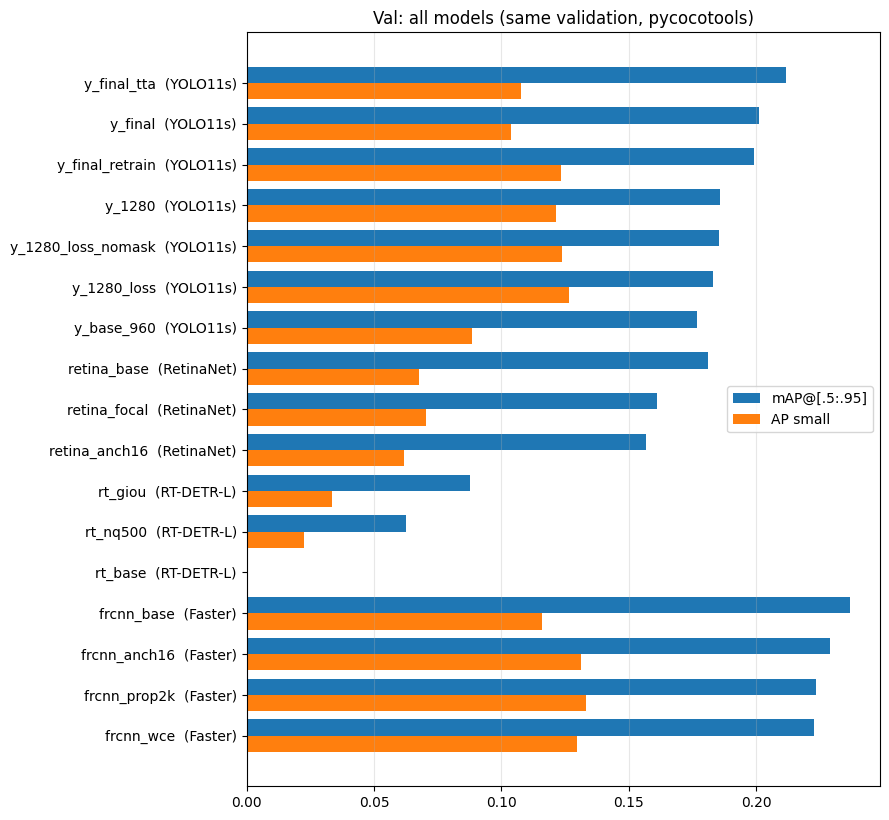

Ignore-region mask (masked -> not masked), delta mAP/AP50/APs: [     0.0025     -0.0057     -0.0025]


In [ ]:
S = SUMMARY.sort_values(["family", "mAP"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 0.4 * len(S) + 1.5)); y = np.arange(len(S))
ax.barh(y + 0.2, S.mAP, 0.4, label="mAP@[.5:.95]"); ax.barh(y - 0.2, S.APs, 0.4, label="AP small")
ax.set_yticks(y); ax.set_yticklabels(S.exp + "  (" + S.family.str.split(" ").str[0] + ")"); ax.legend(); ax.grid(axis="x", alpha=.3)
ax.set_title("Val: all models (same validation, pycocotools)"); plt.tight_layout(); plt.savefig(WORK / "summary_models.png", dpi=110); plt.show()
if {"y_1280_loss", "y_1280_loss_nomask"} <= set(SUMMARY.exp):
    a, b = SUMMARY.set_index("exp").loc[["y_1280_loss", "y_1280_loss_nomask"], ["mAP", "AP50", "APs"]].values
    print("Ignore-region mask (masked -> not masked), delta mAP/AP50/APs:", (b - a).round(4))

### 9.6 Final solution → `submission_final.csv`
`FINAL` defaults to the variant with the best val mAP from section 9.3. **It can be set manually**, e.g. `FINAL = dict(name="final", models=["y_final"])`, if the difference is within noise (see section 9.4: how many clips improved) — a simpler configuration is then safer.
Raw test predictions are cached (`pred_test_*.pkl`) for reproducibility.

In [ ]:
FINAL = dict(BEST_CFG); FINAL["name"] = "final"
print("FINAL CONFIGURATION:", {k: v for k, v in FINAL.items()})
t0 = time.time(); cache, ms = predict_cfg(FINAL, "test", TEST_PATHS)
out = {r.image_id: cache[str(ROOT / r.file_name)] for r in te.itertuples()}
save_preds(out, "test_preds_final.pkl")
path = write_submission(out, WORK / "submission_final.csv"); check_submission(path)
print(f"done: {path} | {(time.time() - t0) / 60:.1f} min")

FINAL CONFIGURATION: {'name': 'final', 'models': ['y_final', 'y_final_last'], 'weights': [1, 1], 'tta': True, 'fuse_iou': 0.55}
OK: 3811 rows, detections/frame: mean=247.1 max=393, empty=0
done: /content/work/submission_final.csv | 9.2 min


## 10. Bonus — temporal consistency (rescoring over neighbouring frames)
Test clips are consecutive frames, so a real object should reappear at almost the same place in frames t-1 and t+1, while false positives usually flicker.
**Method (no extra training):** for every detection, find the best same-class match (IoU >= `thr`) in the neighbouring frames (`win` frames on each side) and blend its score with the neighbours' matched scores:
`s' = (1 - w) * s + w * mean(matched neighbour scores)` (0 when there is no match).
**Evaluation:** the main validation set keeps every 5th frame (too sparse for temporal methods), so here we run inference on **all 2846 val frames** with the same final configuration and compare mAP with and without rescoring on the same frames.
Camera motion is not compensated; IoU between consecutive frames stays high for most objects (see the temporal-correlation analysis in section 1.9).

In [ ]:
def iou_matrix(a, b):
    iw = (np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0])).clip(0)
    ih = (np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1])).clip(0)
    inter = iw * ih
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def temporal_rescore(frames, w=0.3, thr=0.5, win=1):
    out = []
    for t, (b, s, l) in enumerate(frames):
        if len(b) == 0:
            out.append((b, s, l)); continue
        acc, cnt = np.zeros(len(b)), 0
        for dt in range(-win, win + 1):
            if dt == 0 or not (0 <= t + dt < len(frames)): continue
            b2, s2, l2 = frames[t + dt]; cnt += 1
            if len(b2) == 0: continue
            iou = iou_matrix(np.asarray(b, float), np.asarray(b2, float)) * (np.asarray(l)[:, None] == np.asarray(l2)[None, :])
            acc += np.where(iou >= thr, np.asarray(s2)[None, :], 0.0).max(1)
        out.append((b, (1 - w) * np.asarray(s, float) + w * acc / max(cnt, 1), l))
    return out

def rescore_cache(cache, groups, **kw):
    new = dict(cache)
    for g in groups:
        for p, r in zip(g, temporal_rescore([cache[str(p)] for p in g], **kw)): new[str(p)] = r
    return new

In [ ]:
gt_full = load_val_gt(make_val_gt(step=1, name="val_full")); ITEMS_FULL = val_items(gt_full)
FULL_PATHS = [p for _, p, _ in ITEMS_FULL]; print("val frames (all):", len(ITEMS_FULL), "(expected 2846)")
cache_full, _ = predict_cfg(FINAL, "valfull", FULL_PATHS)
by_clip = {}
for iid, p, v in ITEMS_FULL: by_clip.setdefault(v, []).append((gt_full.imgs[iid]["frame_id"], p))
GROUPS_FULL = [[p for _, p in sorted(v)] for v in by_clip.values()]

def eval_full(cache):
    preds, _ = predict_items(lambda p: cache[str(p)], ITEMS_FULL); return preds, coco_eval(gt_full, preds)
base_preds, r0 = eval_full(cache_full)
T_ROWS = [dict(setting="no temporal", **{k: round(r0[k], 4) for k in ["mAP", "AP50", "APs"]})]; T_PREDS = {"no temporal": base_preds}
for w, thr, win in [(0.2, 0.5, 1), (0.4, 0.5, 1), (0.3, 0.4, 1), (0.3, 0.5, 2)]:
    name = f"w={w}, IoU>={thr}, win={win}"
    preds, r = eval_full(rescore_cache(cache_full, GROUPS_FULL, w=w, thr=thr, win=win)); T_PREDS[name] = preds
    T_ROWS.append(dict(setting=name, **{k: round(r[k], 4) for k in ["mAP", "AP50", "APs"]}))
T_TABLE = pd.DataFrame(T_ROWS); display(T_TABLE)

val frames (all): 2846 (expected 2846)


,setting,mAP,AP50,APs
0,no temporal,0.2132,0.4130,0.1084
1,"w=0.2, IoU>=0.5, win=1",0.2162,0.4173,0.1113
2,"w=0.4, IoU>=0.5, win=1",0.2174,0.4178,0.1123
3,"w=0.3, IoU>=0.4, win=1",0.2161,0.4159,0.1108
4,"w=0.3, IoU>=0.5, win=2",0.2169,0.4182,0.1137


In [ ]:
best_t = T_TABLE.iloc[1:].sort_values("mAP").iloc[-1]
_, c0 = eval_report(gt_full, T_PREDS["no temporal"], ITEMS_FULL); _, c1 = eval_report(gt_full, T_PREDS[best_t.setting], ITEMS_FULL)
cmpT = c0[["clip", "obj_per_frame", "mAP"]].merge(c1[["clip", "mAP"]], on="clip", suffixes=("_no_temporal", "_temporal"))
cmpT["delta"] = (cmpT["mAP_temporal"] - cmpT["mAP_no_temporal"]).round(4); display(cmpT)
gain = best_t.mAP - T_TABLE.iloc[0].mAP; n_better = int((cmpT["delta"] > 0).sum())
USE_TEMPORAL = bool(gain > 0.002 and n_better >= 5)
print(f"best: {best_t.setting} | mAP gain = {gain:+.4f} | clips improved: {n_better}/{len(cmpT)} -> USE_TEMPORAL = {USE_TEMPORAL}")

,clip,obj_per_frame,mAP_no_temporal,mAP_temporal,delta
0,uav0000086_00000_v,49.778,0.226,0.223,-0.003
1,uav0000117_02622_v,49.510,0.209,0.211,0.002
2,uav0000137_00458_v,103.382,0.299,0.298,-0.001
3,uav0000182_00000_v,48.680,0.179,0.180,0.001
4,uav0000268_05773_v,13.883,0.083,0.084,0.001
5,uav0000305_00000_v,34.734,0.262,0.273,0.011
6,uav0000339_00001_v,43.738,0.283,0.283,0.000


best: w=0.4, IoU>=0.5, win=1 | mAP gain = +0.0042 | clips improved: 4/7 -> USE_TEMPORAL = False


In [ ]:
if USE_TEMPORAL:
    import re
    w_, thr_, win_ = [float(x) for x in re.findall(r"[-+]?\d*\.?\d+", best_t.setting)]
    TEMPORAL = dict(w=w_, thr=thr_, win=int(win_))
    order = te.sort_values(["clip", "frame"]); groups_test = [[ROOT / f for f in g.file_name] for _, g in order.groupby("clip")]
    cache_t = rescore_cache({str(ROOT / r.file_name): out[r.image_id] for r in te.itertuples()}, groups_test, **TEMPORAL)
    out_t = {r.image_id: cache_t[str(ROOT / r.file_name)] for r in te.itertuples()}
    save_preds(out_t, "test_preds_final_temporal.pkl")
    path_t = write_submission(out_t, WORK / "submission_final_temporal.csv"); check_submission(path_t); print("temporal parameters:", TEMPORAL)
else:
    TEMPORAL = None; print("Temporal rescoring did not help consistently on validation -> not applied (submission_final.csv stays final).")

Temporal rescoring did not help consistently on validation -> not applied (submission_final.csv stays final).


## 11. Bonus — custom architectural decisions (P2 head for small objects)

**Hypothesis.** Section 1 showed that about a quarter of the objects are small and the median object is only ~46 px in the original frames. After resizing to a long side of 1280 px, many objects are only a few cells wide on the finest YOLO11 level (stride 8), so the standard P3–P5 head has little spatial resolution to localise them. Adding a **P2/4 head** gives every small object 2x more cells in each direction, at the price of ~4x more anchors on that level.

**Experiments (identical protocol to `y_1280_loss`: 1280 px, 3 epochs, `box=10`, `cls=1`, same data):**

| run (`EXP`) | change | what it tests |
|---|---|---|
| `y_1280_loss` | baseline P3–P5 | reference |
| `y_p2_1280` | + P2/4 head (P2–P5) | does finer resolution help small objects? |
| `y_p2nop5_1280` | P2/4 head, P5/32 head removed (P2–P4) | are the large-object heads still needed, i.e. is the extra P2 compute paid for by dropping P5? |

Both new runs use `batch=6` instead of 8 (the P2 head needs more GPU memory). The pretrained `yolo11s.pt` initialises the backbone; the new head layers start from scratch, so a 3-epoch comparison is deliberately harder for the custom models — an improvement over the baseline is therefore a conservative result.

123,474 objects from 2697 label files; median size 30.4 px at 1280 px


,level,stride,objects < 2 cells (%),objects < 1 cell (%),median size in cells
0,P2/4,4,0.6,0.0,7.6
1,P3/8,8,9.9,0.6,3.8
2,P4/16,16,54.2,9.9,1.9
3,P5/32,32,89.1,54.2,0.9


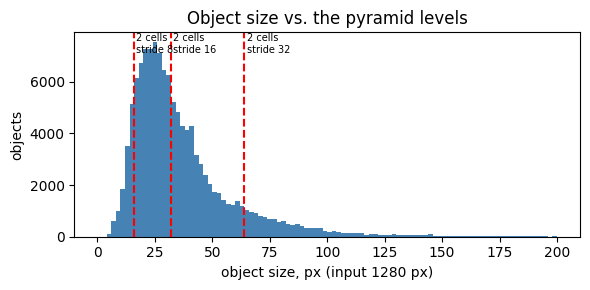

In [35]:
import matplotlib.pyplot as plt
DS_ = find_ds("ds_s3_mask")
files = sorted((DS_ / "labels" / "train").glob("*.txt"))[::3]
wh = []
for f in files:
    if f.stat().st_size == 0: continue
    a = np.loadtxt(f, ndmin=2)
    wh.append(a[:, 3:5] * np.array([LONG_SIDE, LONG_SIDE * 9 / 16]))
wh = np.concatenate(wh); size = np.sqrt(wh[:, 0] * wh[:, 1]); print(f"{len(size):,} objects from {len(files)} label files; median size {np.median(size):.1f} px at {LONG_SIDE} px")
rows = [dict(level=f"P{int(np.log2(s))}/{s}", stride=s, **{"objects < 2 cells (%)": round((size < 2 * s).mean() * 100, 1),
         "objects < 1 cell (%)": round((size < s).mean() * 100, 1), "median size in cells": round(float(np.median(size) / s), 1)})
        for s in [4, 8, 16, 32]]
display(pd.DataFrame(rows))
plt.figure(figsize=(6, 3)); plt.hist(size, bins=100, range=(0, 200), color="steelblue")
for s in [8, 16, 32]: plt.axvline(2 * s, color="r", ls="--"); plt.text(2 * s + 1, plt.ylim()[1] * 0.9, f"2 cells\nstride {s}", fontsize=7)
plt.xlabel(f"object size, px (input {LONG_SIDE} px)"); plt.ylabel("objects"); plt.title("Object size vs. the pyramid levels"); plt.tight_layout(); plt.show()

### 11.1 Analytic check: pyramid levels vs. object size

**Reading the table.** The row for stride 8 is the key number: the share of objects narrower than 2 cells is what the standard head must localise with almost no spatial resolution. If that share is substantial, the P2 head has room to help; the row for stride 32 shows how few objects actually need the coarse P5 level (large objects: ~12 %, mostly buses and trucks).

### 11.2 Cost of the custom models

In [32]:
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils.torch_utils import get_flops
ARCH_CFG = {"y_1280_loss": "yolo11s.yaml", "y_p2_1280": "yolo11s-p2.yaml", "y_p2nop5_1280": "yolo11s-p2_nop5.yaml"}
cost = []
for exp, f in ARCH_CFG.items():
    m = DetectionModel(f, ch=3, nc=8, verbose=False)
    cost.append(dict(exp=exp, config=f, params_M=round(sum(p.numel() for p in m.parameters()) / 1e6, 2),
                     GFLOPs_1280=round(get_flops(m, imgsz=1280), 1), strides=[int(s) for s in m.stride.tolist()]))
COST = pd.DataFrame(cost); display(COST)

Overriding model.yaml nc=80 with nc=8
Overriding model.yaml nc=80 with nc=8
Overriding model.yaml nc=80 with nc=8


,exp,config,params_M,GFLOPs_1280,strides
0,y_1280_loss,yolo11s.yaml,9.43,88.2,"[8, 16, 32]"
1,y_p2_1280,yolo11s-p2.yaml,9.58,117.8,"[4, 8, 16, 32]"
2,y_p2nop5_1280,yolo11s-p2_nop5.yaml,7.09,109.9,"[4, 8, 16]"


### 11.3 Training the custom models
Run section 4 twice with `EXP = "y_p2_1280"` and `EXP = "y_p2nop5_1280"` (both presets exist in 4.1, `EPOCHS = 3`, `SMOKE = False`), running the backup cell after each run. Section 3.3 must have been executed in the session first (it writes the YAML files). Then continue below.

### 11.4 Comparison with the baseline

available runs: ['y_1280_loss', 'y_p2_1280', 'y_p2nop5_1280']


,train_min,ms_per_frame,mAP,AP50,AP75,APs,APm,APl,params_M,GFLOPs_1280
exp,,,,,,,,,,
y_1280_loss,28.6,56.0,0.1829,0.3695,NaN,0.1264,0.1819,0.2901,9.43,88.2
y_p2_1280,41.8,63.0,0.1835,0.3857,0.1502,0.1112,0.1695,0.3247,9.58,117.8
y_p2nop5_1280,40.3,93.0,0.1862,0.3925,0.1487,0.1072,0.1811,0.3276,7.09,109.9


Difference to the baseline y_1280_loss (positive = better):


,mAP,AP50,APs,APm,APl,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
exp,,,,,,,,,,,,,
y_p2_1280,0.0006,0.0162,-0.0152,-0.0124,0.0346,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
y_p2nop5_1280,0.0033,0.0230,-0.0192,-0.0008,0.0375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


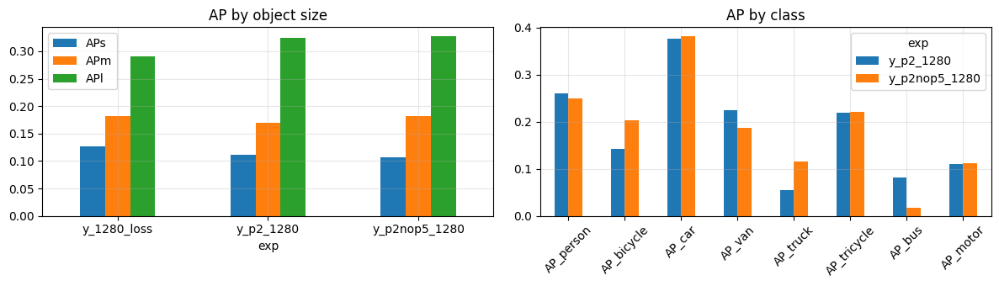

In [36]:
R_ = pd.read_csv(WORK / "results_all.csv")
R_ = R_.drop_duplicates("exp", keep="last").set_index("exp")
R_.loc["y_1280_loss", ["train_min", "ms_per_frame", "mAP", "AP50", "APs", "APm", "APl"]] = [28.6, 56, 0.1829, 0.3695, 0.1264, 0.1819, 0.2901]   # baseline from an earlier session
have = [e for e in ARCH_CFG if e in R_.index]; print("available runs:", have)
cols = ["train_min", "ms_per_frame", "mAP", "AP50", "AP75", "APs", "APm", "APl"]
A = R_.loc[have, cols].join(COST.set_index("exp")[["params_M", "GFLOPs_1280"]])
display(A.round(4))
if "y_1280_loss" in have and len(have) > 1:
    base = R_.loc["y_1280_loss"]; D = (R_.loc[have[1:], ["mAP", "AP50", "APs", "APm", "APl"] + [f"AP_{c}" for c in CLASSES]] - base[["mAP", "AP50", "APs", "APm", "APl"] + [f"AP_{c}" for c in CLASSES]]).round(4)
    print("Difference to the baseline y_1280_loss (positive = better):"); display(D)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    R_.loc[have, ["APs", "APm", "APl"]].plot.bar(ax=ax[0], rot=0); ax[0].set_title("AP by object size"); ax[0].grid(alpha=.3)
    have_cls = [e for e in have if pd.notna(R_.loc[e, "AP_person"])]
    R_.loc[have_cls, [f"AP_{c}" for c in CLASSES]].T.plot.bar(ax=ax[1], rot=45); ax[1].set_title("AP by class"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(WORK / "arch_comparison.png", dpi=110); plt.show()

### 11.5 Failure cases of the custom models vs. the baseline
Per-frame error taxonomy (score ≥ 0.3, IoU ≥ 0.5) summed over the validation frames, and the frame where the P2 model gains the most small objects compared with the baseline (green = ground truth, red = predictions). This shows *where* the architectural change helps or hurts, beyond the single mAP number.

,n_gt,TP,CONF,FP,FN,FN_small
y_1280_loss,22906,12294,1879,4083,8733,2667
y_p2_1280,22906,12511,1868,4725,8527,2531
y_p2nop5_1280,22906,12210,1780,4796,8916,2667


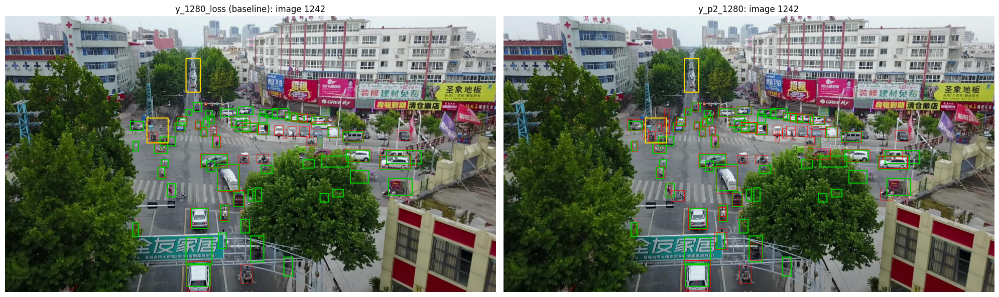

frame 1242: 9 fewer small-object misses with y_p2_1280


In [37]:
import os
CKPT_ = Path(os.environ.get("CKPT_DIR", "/content/drive/MyDrive/hw2_out"))
FA = {}
for e in have:
    f = next((p for p in [WORK / f"val_preds_{e}.json", CKPT_ / f"val_preds_{e}.json"] if p.exists()), None)
    if f: pr = json.load(open(f)); FA[e] = (pr, analyze_failures(gt, pr, ITEMS, thr=0.3))
display(pd.DataFrame({e: fa[["n_gt", "TP", "CONF", "FP", "FN", "FN_small"]].sum() for e, (_, fa) in FA.items()}).T)
if "y_1280_loss" in FA and len(FA) > 1:
    other = [e for e in FA if e != "y_1280_loss"][0]; (pb, fb), (po, fo) = FA["y_1280_loss"], FA[other]
    d = (fb.set_index("image_id").FN_small - fo.set_index("image_id").FN_small); iid = int(d.idxmax()); path = {i: p for i, p, _ in ITEMS}[iid]
    fig, ax = plt.subplots(1, 2, figsize=(20, 6))
    for a_, (pp, nm) in zip(ax, [(pb, "y_1280_loss (baseline)"), (po, other)]): a_.imshow(draw_case(gt, pp, iid, path)); a_.axis("off"); a_.set_title(f"{nm}: image {iid}")
    plt.tight_layout(); plt.savefig(WORK / "arch_failure_case.png", dpi=80); plt.show()
    print(f"frame {iid}: {int(d.max())} fewer small-object misses with {other}")

### 11.6 Interpretation

**Pre-registered expectation (11.1).** At 1280 px the median object is 30 px (3.8 cells at stride 8). Only 9.9 % of the objects are narrower than 2 cells at stride 8 and 0.6 % at stride 4, so a P2 head can only help a small tail of very small objects. At the other end, 54 % of the objects are smaller than one cell at stride 32, so the P5 head mostly serves the ~12 % of large objects (buses, trucks). Expectation: a modest gain on `APs` from P2, and a P5 head that could be removed at little cost.

**Results (validation, 571 frames; baseline `y_1280_loss`).**

| | mAP | AP50 | APs | APm | APl | params | GFLOPs @1280 | train time |
|---|---|---|---|---|---|---|---|---|
| `y_1280_loss` (P3–P5) | 0.1829 | 0.3695 | 0.1264 | 0.1819 | 0.2901 | 9.43 M | 88.2 | 28.6 min |
| `y_p2_1280` (P2–P5) | 0.1835 (+0.001) | 0.3857 (+0.016) | 0.1112 (−0.015) | 0.1695 (−0.012) | 0.3247 (+0.035) | 9.58 M | 117.8 (+34 %) | 41.8 min |
| `y_p2nop5_1280` (P2–P4) | 0.1862 (+0.003) | 0.3925 (+0.023) | 0.1072 (−0.019) | 0.1811 (−0.001) | 0.3276 (+0.038) | 7.09 M (−25 %) | 109.9 (+25 %) | 40.3 min |

* **Small objects: the hypothesis was not confirmed.** Overall mAP did not change (+0.001 and +0.003, within the run-to-run noise we measured elsewhere), and `APs` *dropped* by 0.015–0.019. The failure-case table (11.5, score ≥ 0.3, IoU ≥ 0.5) explains part of it: with the P2 head, small-object misses fell by 5 % (2667 → 2531) and true positives rose by 217, but false positives rose by 642 (+16 %). Recall on small objects improved slightly, precision fell more, hence the lower `APs`. The example frame (a dense junction) shows 9 fewer small-object misses with P2, yet the same frame also gets more spurious boxes. The baseline has no per-class AP in the log (it was trained in an earlier session), so the per-class effect on `person`, `motor`, `bicycle` can only be compared between the two P2 variants, where it is similar.
* **Large objects improved instead:** `APl` +0.035/+0.038. We did not test why; a possible (untested) explanation is that the extra top-down/bottom-up path through the P2 level changes the features that the P3–P5 heads receive. It should be treated as a hypothesis, not a finding.
* **Cost.** Parameters hardly change for the P2 head (+1.6 %), but compute does: +34 % GFLOPs and +46 % training time (batch 6 instead of 8 also contributes). The measured ms/frame (56 → 63 → 93) is not consistent with the FLOPs (the P2–P4 model cannot be slower than P2–P5) and is probably Colab GPU noise, so we draw no conclusion about inference speed. Overall the P2 head costs ~⅓ more compute for no mAP gain.
* **Large objects / P5.** Removing the P5 head did not hurt `APl` (0.3276 vs. 0.3247) or mAP, and saved 25 % of the parameters, consistent with 11.1 (most objects are smaller than a stride-32 cell). At class level the bus AP is much lower without P5 (≈0.02 vs. ≈0.08) while truck is higher (≈0.12 vs. ≈0.06); buses are only 0.2 % of the validation objects (264 instances), so these class numbers are too noisy to conclude that P5 is or is not needed for buses.
* **Caveats.** Three epochs and one seed per model; the new head layers start from scratch while the rest is pretrained, and the baseline used batch 8 vs. 6. The run-to-run noise of the same configuration was ≈0.002 mAP on validation (`y_final`, 0.2011 vs. 0.1993) and ≈0.023 on the public leaderboard (0.2526 vs. 0.2299), so only the `APs`/`APl` shifts (0.015–0.038) are larger than the noise; the mAP differences are not.

**Decision.** Neither custom head was adopted: the P2 head did not improve mAP or small-object AP and cost +34 % compute; removing P5 is parameter-efficient but did not make the model faster. The final model stays the standard YOLO11s (`y_final`).

## 12. Bonus — visualisation and Weights & Biases logging

Everything is logged **after** training (the training cells stay unchanged and cheap): one W&B run per experiment with the configuration and the per-epoch curves, a run with the model comparison table, annotated validation predictions, **Grad-CAM** maps for success and failure cases, and a **t-SNE** of per-object neck features.

Log in with your own W&B account when `wandb.login()` asks for the API key (https://wandb.ai/authorize). Without a key the logs are written offline (`./wandb`) and can be uploaded later with `wandb sync`. To submit the project, make it public in W&B (project settings → Visibility) and put the link in the README/report.

In [3]:
import os, wandb
os.environ.pop("WANDB_DISABLED", None)
WANDB_PROJECT = "hw2-visdrone-vid"
os.environ["WANDB_MODE"] = "online"
CKPT = Path(os.environ.get("CKPT_DIR", "/content/drive/MyDrive/hw2_out"))
family = lambda e: "yolo (one-stage anchor-free)" if e.startswith("y") else "faster-rcnn (two-stage)" if e.startswith("frcnn") else "retinanet (one-stage anchor-based)" if e.startswith("retina") else "rt-detr (query-based)" if e.startswith("rt") else "other"

### 12.1 One run per experiment: configuration, final metrics, per-epoch curves

In [ ]:
_parts = [pd.read_csv(p) for p in [CKPT / "results_all.csv", WORK / "results_all.csv"] if p.exists()]
R_ALL = pd.concat(_parts, ignore_index=True).drop_duplicates("exp", keep="last")      # Drive version first, newer rows from this session override it
METRICS = ["mAP", "AP50", "AP75", "APs", "APm", "APl"] + [f"AP_{c}" for c in CLASSES] + ["train_min", "ms_per_frame"]
for r in R_ALL.to_dict("records"):
    cfg_ = {k: v for k, v in r.items() if k not in METRICS and pd.notna(v)}
    run = wandb.init(project=WANDB_PROJECT, name=r["exp"], group=family(r["exp"]), config=cfg_, reinit=True)
    cv = next((p for p in [WORK / f"curve_{r['exp']}.csv", CKPT / f"curve_{r['exp']}.csv"] if p.exists()), None)
    if cv is not None:
        c = pd.read_csv(cv); c.columns = [x.strip() for x in c.columns]
        for i, row in c.iterrows():
            wandb.log({k: float(v) for k, v in row.items() if k != "epoch" and pd.notna(v)}, step=int(row.get("epoch", i)))
    run.summary.update({k: float(r[k]) for k in METRICS if k in r and pd.notna(r[k])})
    run.finish(); print("logged", r["exp"], "| curve:", "yes" if cv is not None else "no")
run = wandb.init(project=WANDB_PROJECT, name="model_comparison", group="summary", reinit=True)
wandb.log({"results_table": wandb.Table(dataframe=R_ALL[["exp"] + [m for m in METRICS if m in R_ALL]].round(4))})
if "arch_comparison.png" in os.listdir(WORK): wandb.log({"architecture_bonus": wandb.Image(str(WORK / "arch_comparison.png"))})
run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


### 12.2 Validation predictions with boxes (ground truth vs. predictions) for every required model
One W&B table per model family (the best run of YOLO11, Faster R-CNN, RetinaNet and RT-DETR by validation mAP), so the same frames can be compared across detectors. In the W&B image viewer the `ground_truth` / `prediction` layers can be toggled and filtered by class and score. Two frames per validation clip; predictions with score ≥ 0.3; grey boxes are ignore regions.

In [40]:
from PIL import Image
def load_val_preds(exp):
    f = next((p for p in [WORK / f"val_preds_{exp}.json", CKPT / f"val_preds_{exp}.json"] if p.exists()), None)
    return json.load(open(f)) if f else None
LBL = {i: c for i, c in enumerate(CLASSES)}; LBL[8] = "ignore region"
PRED_BY = defaultdict(list)       # filled for the model being visualised
def set_preds(preds):
    PRED_BY.clear()
    for p in preds: PRED_BY[p["image_id"]].append(p)

def wb_image(path, iid, thr=0.3, max_side=1280):
    im = Image.open(path).convert("RGB"); W, H = im.size; s = min(1.0, max_side / max(W, H)); im = im.resize((round(W * s), round(H * s)))
    def bx(b, cid, cap, score=None):
        d = dict(position=dict(minX=b[0] * s, minY=b[1] * s, maxX=(b[0] + b[2]) * s, maxY=(b[1] + b[3]) * s), class_id=int(cid), box_caption=cap, domain="pixel")
        if score is not None: d["scores"] = {"conf": float(score)}
        return d
    g = [bx(a["bbox"], 8 if a.get("iscrowd", 0) else a["category_id"] - 1, "ignore" if a.get("iscrowd", 0) else CLASSES[a["category_id"] - 1]) for a in gt.imgToAnns.get(iid, [])]
    p = [bx(q["bbox"], q["category_id"] - 1, f"{CLASSES[q['category_id'] - 1]} {q['score']:.2f}", q["score"]) for q in PRED_BY.get(iid, []) if q["score"] >= thr]
    return wandb.Image(im, boxes={"ground_truth": dict(box_data=g, class_labels=LBL), "prediction": dict(box_data=p, class_labels=LBL)}), len(g), len(p)

BEST_PER_FAMILY = {}
for r in R_ALL.sort_values("mAP", ascending=False).to_dict("records"):
    if load_val_preds(r["exp"]) is not None: BEST_PER_FAMILY.setdefault(family(r["exp"]), r["exp"])
print("models visualised:", BEST_PER_FAMILY)
run = wandb.init(project=WANDB_PROJECT, name="val_predictions", group="visualisation", reinit=True)
for fam, exp in BEST_PER_FAMILY.items():
    set_preds(load_val_preds(exp)); tab = wandb.Table(columns=["model", "clip", "image_id", "n_gt", "n_pred(>=0.3)", "image"])
    for clip in sorted({v for _, _, v in ITEMS}):
        fr = [(i, p) for i, p, v in ITEMS if v == clip]
        for i, p in [fr[len(fr) // 4], fr[3 * len(fr) // 4]]:
            img, ng, npred = wb_image(p, i); tab.add_data(exp, clip, i, ng, npred, img)
    wandb.log({f"val_predictions/{exp}": tab}); print(exp, "rows:", len(tab.data))
run.finish()
set_preds(load_val_preds("y_final") or VAL_PREDS[FINAL["name"]])

models visualised: {'yolo (one-stage anchor-free)': 'y_p2nop5_1280', 'rt-detr (query-based)': 'rt_giou'}


y_p2nop5_1280 rows: 14
rt_giou rows: 14


### 12.3 Grad-CAM for YOLO11
For a chosen ground-truth object, the target is the **class score of the detection whose predicted centre falls in that object** (the most confident one). The gradient of this score with respect to a feature map gives per-channel weights; the map is `ReLU(sum_k w_k * A_k)`. We look at the backbone output and the three neck levels to see *which pyramid level and which image region* supports the decision. Cases are selected automatically from the validation predictions: small / large objects that were found (**hit**) and objects that were missed (**miss**, no same-class prediction with IoU ≥ 0.5 and score ≥ 0.3).

In [41]:
import torch, cv2
DEV = "cuda" if torch.cuda.is_available() else "cpu"
LAYERS_BASE = {"backbone out (10)": 10, "neck P3/8 (16)": 16, "neck P4/16 (19)": 19, "neck P5/32 (22)": 22}
LAYERS_P2   = {"backbone out (10)": 10, "neck P2/4 (19)": 19, "neck P3/8 (22)": 22, "neck P4/16 (25)": 25}

class YoloCam:
    def __init__(self, weights, layers, imgsz=1280, device=DEV):
        self.m = YOLO(str(weights)).model.float().to(device).eval(); self.dev, self.imgsz, self.acts = device, imgsz, {}
        for p in self.m.parameters(): p.requires_grad_(True)
        for name, i in layers.items(): self.m.model[i].register_forward_hook(self._hook(name))
    def _hook(self, name):
        def h(mod, inp, out): self.acts[name] = out
        return h
    def prep(self, path):
        im = cv2.imread(str(path)); H, W = im.shape[:2]; s = self.imgsz / max(H, W)
        im = cv2.resize(im, (round(W * s), round(H * s)), interpolation=cv2.INTER_AREA); nh, nw = im.shape[:2]
        im = cv2.copyMakeBorder(im, 0, (32 - nh % 32) % 32, 0, (32 - nw % 32) % 32, cv2.BORDER_CONSTANT, value=(114, 114, 114))
        x = torch.from_numpy(im[..., ::-1].copy()).permute(2, 0, 1)[None].float().div(255).to(self.dev)
        return x, s, (nh, nw)
    def cam(self, path, box, cls):
        """box = xyxy in original pixels, cls = 0-based class. Returns {layer: heatmap in [0,1]}, target score, scale, (nh, nw) or None."""
        x, s, (nh, nw) = self.prep(path); x.requires_grad_(True); self.acts.clear()
        with torch.enable_grad():
            out = self.m(x); y = out[0] if isinstance(out, (list, tuple)) else out
            xc, yc, sc = y[0, 0], y[0, 1], y[0, 4 + cls]; x1, y1, x2, y2 = [v * s for v in box]
            inside = (xc >= x1) & (xc <= x2) & (yc >= y1) & (yc <= y2)
            if not bool(inside.any()): return None
            target = torch.where(inside, sc, torch.full_like(sc, -1.0)).max()
            maps = {}
            for name, a in self.acts.items():
                g = torch.autograd.grad(target, a, retain_graph=True, allow_unused=True)[0]
                if g is None: maps[name] = np.zeros(a.shape[2:], np.float32); continue
                c = torch.relu((g.mean((2, 3), keepdim=True) * a).sum(1))[0].detach().cpu().numpy(); maps[name] = c / (c.max() + 1e-9)
        return maps, float(target), s, (nh, nw), x.shape[2:]

def iou_xywh(a, b):
    iw = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0])); ih = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return iw * ih / (a[2] * a[3] + b[2] * b[3] - iw * ih + 1e-9)
def best_iou(a, c, iid, thr=0.3):
    return max([iou_xywh(a["bbox"], q["bbox"]) for q in PRED_BY.get(iid, []) if q["category_id"] - 1 == c and q["score"] >= thr] or [0.0])

def pick_cases(n_frames=150, seed=0):
    cases, rng = {}, np.random.default_rng(seed)
    for k in rng.permutation(len(ITEMS))[:n_frames]:
        iid, path, vid = ITEMS[k]
        for a in gt.imgToAnns.get(iid, []):
            if a.get("iscrowd", 0): continue
            w, h = a["bbox"][2:]; sz = (w * h) ** 0.5; c = a["category_id"] - 1
            if sz < 8: continue
            key = f"{'hit' if best_iou(a, c, iid) >= 0.5 else 'miss'}_{'small' if sz < 32 else 'large' if sz > 96 else 'medium'}"
            if key not in cases: cases[key] = dict(path=path, iid=iid, box=[a["bbox"][0], a["bbox"][1], a["bbox"][0] + w, a["bbox"][1] + h], cls=c, clip=vid)
    return cases

def show_cases(cm, cases, title=""):
    keys = [k for k in ["hit_small", "hit_large", "miss_small", "miss_medium"] if k in cases]
    names = list(cm.acts) if cm.acts else list(LAYERS_BASE)
    fig, ax = plt.subplots(len(keys), 1 + len(LAYERS_BASE), figsize=(3.2 * (1 + len(LAYERS_BASE)), 3.2 * max(len(keys), 1)), squeeze=False)
    for r, k in enumerate(keys):
        cs = cases[k]; res = cm.cam(cs["path"], cs["box"], cs["cls"])
        im = cv2.cvtColor(cv2.imread(str(cs["path"])), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
        x1, y1, x2, y2 = cs["box"]; m = max(x2 - x1, y2 - y1) * 2.5 + 40; cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        X1, Y1, X2, Y2 = int(max(cx - m / 2, 0)), int(max(cy - m / 2, 0)), int(min(cx + m / 2, W)), int(min(cy + m / 2, H))
        crop = im[Y1:Y2, X1:X2]; ax[r, 0].imshow(crop); ax[r, 0].add_patch(plt.Rectangle((x1 - X1, y1 - Y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=1.5))
        ax[r, 0].set_title(f"{k}: {CLASSES[cs['cls']]}", fontsize=8); ax[r, 0].axis("off")
        for j in range(len(LAYERS_BASE)): ax[r, 1 + j].axis("off")
        if res is None: ax[r, 1].text(0.1, 0.5, "no detection centre inside the box", fontsize=8); continue
        maps, tgt, s, (nh, nw), (ph, pw) = res
        for j, (name, mp) in enumerate(maps.items()):
            heat = cv2.resize(mp, (pw, ph))[:nh, :nw]; heat = cv2.resize(heat, (W, H))[Y1:Y2, X1:X2]
            ax[r, 1 + j].imshow(crop); ax[r, 1 + j].imshow(heat, cmap="jet", alpha=0.5, vmin=0, vmax=1)
            ax[r, 1 + j].add_patch(plt.Rectangle((x1 - X1, y1 - Y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=1)); ax[r, 1 + j].set_title(f"{name}\nscore={tgt:.2f}" if j == 0 else name, fontsize=8)
    plt.suptitle(title); plt.tight_layout(); return fig

cases: {'miss_medium': ('uav0000268_05773_v', 'car'), 'miss_small': ('uav0000268_05773_v', 'person'), 'hit_medium': ('uav0000268_05773_v', 'car'), 'miss_large': ('uav0000268_05773_v', 'truck'), 'hit_large': ('uav0000268_05773_v', 'car'), 'hit_small': ('uav0000086_00000_v', 'person')}


/tmp/ipykernel_78116/964874540.py:34: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return maps, float(target), s, (nh, nw), x.shape[2:]


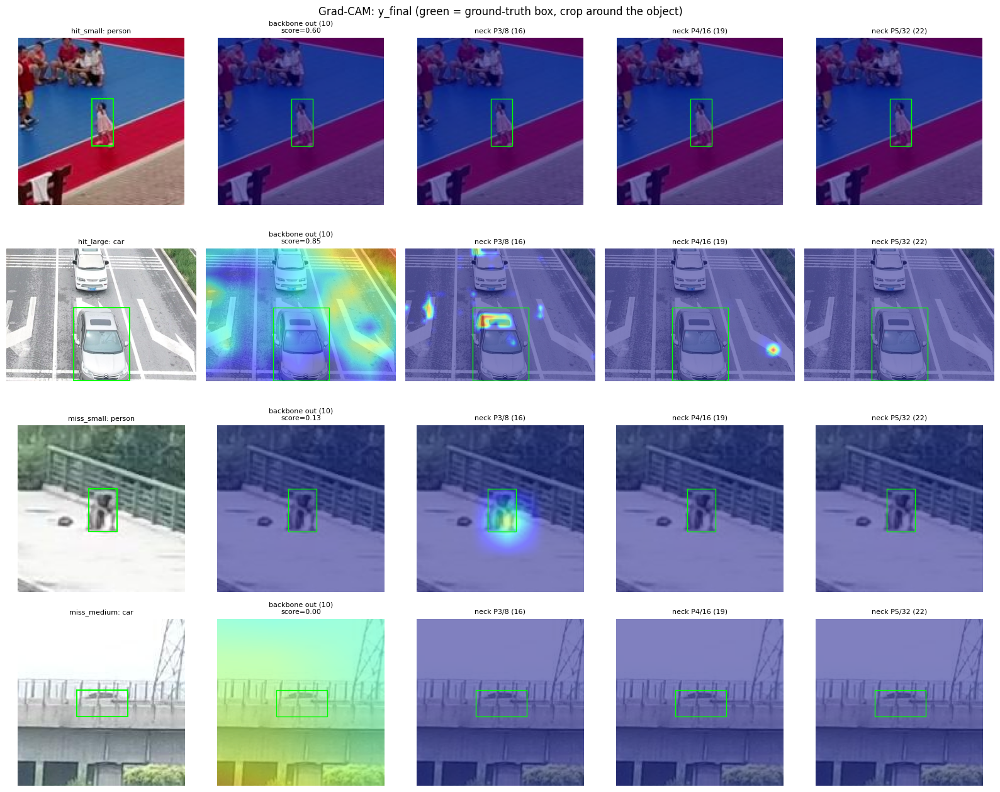

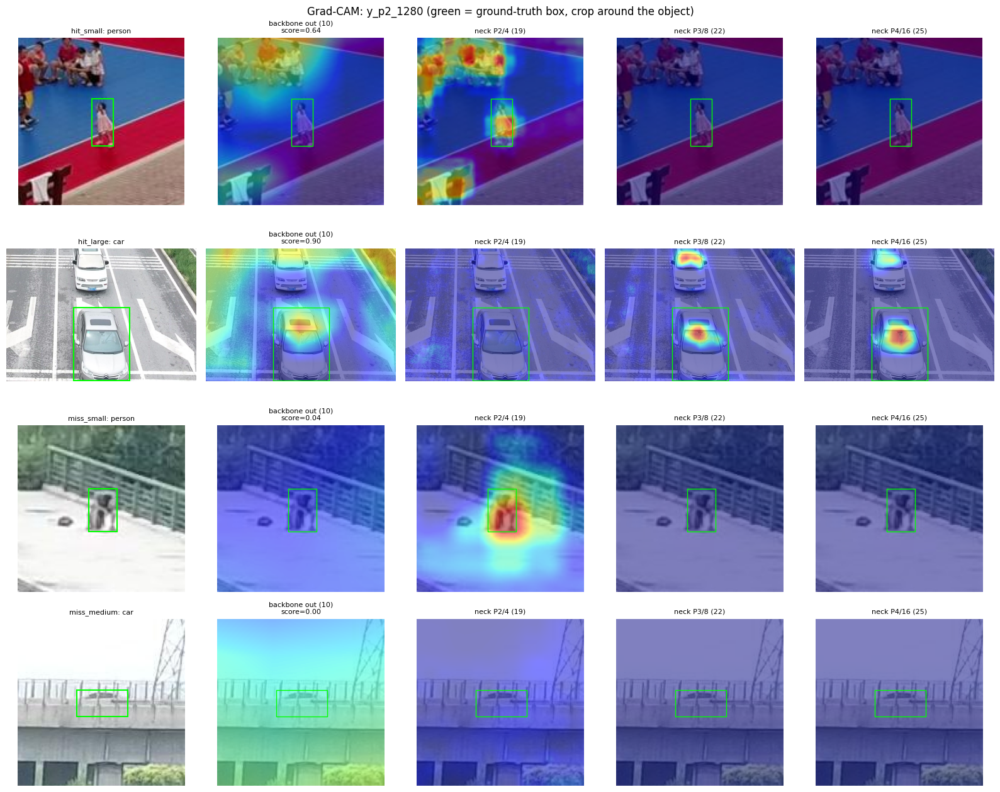

In [42]:
VIS_MODELS = {"y_final": (CKPT / "best_y_final.pt", LAYERS_BASE), "y_p2_1280": (CKPT / "best_y_p2_1280.pt", LAYERS_P2)}   # the second one only if trained (section 11)
VIS_MODELS = {k: v for k, v in VIS_MODELS.items() if v[0].exists()}; CASES = pick_cases(); print("cases:", {k: (v["clip"], CLASSES[v["cls"]]) for k, v in CASES.items()})
run = wandb.init(project=WANDB_PROJECT, name="gradcam", group="visualisation", reinit=True)
for name, (w, layers) in VIS_MODELS.items():
    cm = YoloCam(w, layers); fig = show_cases(cm, CASES, title=f"Grad-CAM: {name} (green = ground-truth box, crop around the object)")
    fig.savefig(WORK / f"gradcam_{name}.png", dpi=110); wandb.log({f"gradcam/{name}": wandb.Image(fig)}); plt.show(); plt.close(fig); del cm
run.finish()

**How to read the maps** (fill in from the figures — the notebook cannot do this for you): for hits, check whether the warm region sits on the object itself or on its context (road, neighbouring cars); for the small-object cases, which level (P3 vs. P4/P5) carries the signal; for the misses, whether the maps are diffuse/absent (the network never "saw" the object) or concentrated on the wrong region (confusion with the background or another class). If the P2 model was trained, compare its P2 map on the same small cases.

### 12.4 t-SNE of per-object neck features
For ground-truth objects in 150 random validation frames, we take the **P4/16 neck feature vector at the cell containing the object centre** (256 dimensions in YOLO11s), reduce it with PCA to 50 dimensions and embed it with t-SNE. The same embedding is coloured by class, by object size and by whether the object was detected (IoU ≥ 0.5, score ≥ 0.3). Clusters by class show what the network separates well; mixing of small objects and of missed objects shows where the representation is weak.

**How to read it** (fill in): are the classes separated or do `car`/`van`/`truck` overlap (expected: they are visually similar from above)? Do the small objects form their own region regardless of class? Are the undetected objects concentrated in a region — that is where the model's representation is weakest.

The project link for the submission is the W&B workspace `hw2-visdrone-vid` (make it public in the project settings).

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
@torch.no_grad()
def object_features(weights, layer_name, layer_idx, n_frames=150, per_frame=20, seed=0):
    cm = YoloCam(weights, {layer_name: layer_idx}); rng = np.random.default_rng(seed); F, M = [], []
    for k in rng.permutation(len(ITEMS))[:n_frames]:
        iid, path, vid = ITEMS[k]; g = [a for a in gt.imgToAnns.get(iid, []) if not a.get("iscrowd", 0) and (a["bbox"][2] * a["bbox"][3]) ** 0.5 >= 8]
        if not g: continue
        x, s, _ = cm.prep(path); cm.acts.clear(); cm.m(x); A = cm.acts[layer_name][0]; stride = x.shape[3] / A.shape[2]
        for a in [g[i] for i in rng.permutation(len(g))[:per_frame]]:
            cx, cy = (a["bbox"][0] + a["bbox"][2] / 2) * s, (a["bbox"][1] + a["bbox"][3] / 2) * s; sz = (a["bbox"][2] * a["bbox"][3]) ** 0.5; c = a["category_id"] - 1
            i, j = min(int(cx / stride), A.shape[2] - 1), min(int(cy / stride), A.shape[1] - 1)
            F.append(A[:, j, i].float().cpu().numpy()); M.append(dict(cls=CLASSES[c], size="small" if sz < 32 else "large" if sz > 96 else "medium", detected=bool(best_iou(a, c, iid) >= 0.5), clip=vid))
    del cm; return np.stack(F), pd.DataFrame(M)

_name, (_w, _layers) = next(iter(VIS_MODELS.items()))
FEAT, META = object_features(_w, "neck P4/16 (19)", 19) if _name == "y_final" else object_features(_w, "neck P4/16 (25)", 25)
Z = TSNE(n_components=2, perplexity=min(30, len(FEAT) // 4), init="pca", random_state=0).fit_transform(PCA(n_components=min(50, FEAT.shape[1], len(FEAT) - 1), random_state=0).fit_transform(FEAT))
META["x"], META["y"] = Z[:, 0], Z[:, 1]; print(len(META), "objects;", META["detected"].mean().round(3), "detected")
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a_, col, title in zip(ax, ["cls", "size", "detected"], ["class", "object size", "detected (IoU >= 0.5)"]):
    for v, d in META.groupby(col): a_.scatter(d.x, d.y, s=6, alpha=0.6, label=str(v))
    a_.set_title(f"t-SNE of P4/16 neck features by {title}"); a_.legend(markerscale=2, fontsize=7); a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.savefig(WORK / "tsne_p4.png", dpi=110); plt.show()
run = wandb.init(project=WANDB_PROJECT, name="tsne", group="visualisation", reinit=True)
wandb.log({"tsne/p4_features": wandb.Image(str(WORK / "tsne_p4.png")), "tsne/points": wandb.Table(dataframe=META)}); run.finish()


**How to read it** (fill in): are the classes separated or do `car`/`van`/`truck` overlap (expected: they are visually similar from above)? Do the small objects form their own region regardless of class? Are the undetected objects concentrated in a region — that is where the model's representation is weakest.

The project link for the submission is the W&B workspace `hw2-visdrone-vid`

## 13. Reproducibility
### 13.1 Versions, configuration and dependencies

In [ ]:
vers = {}
for pkg in ["ultralytics", "torch", "torchvision", "ensemble-boxes", "pycocotools", "numpy", "wandb", "scikit-learn"]:
    try: vers[pkg] = imd.version(pkg)
    except Exception: vers[pkg] = "n/a"
info = dict(final=FINAL, temporal=TEMPORAL, models={k: str(v["w"].name) for k, v in MODEL_CFG.items()}, versions=vers,
            training="notebook 03: YOLO11s, seed=0, ds_s3_mask (every 3rd frame, 1280 px, ignore regions masked)", val="571 frames, 7 val clips, pycocotools (iscrowd, maxDets=500)")
json.dump(info, open(WORK / "final_config.json", "w"), indent=1, ensure_ascii=False, default=str); print(json.dumps(info, indent=1, ensure_ascii=False, default=str))
backup()

### 13.2 How to reproduce
1. Colab (T4 GPU): mount Drive, unzip the competition archive (section 0), run sections 1–3 (EDA, preprocessing, utilities, custom configs).
2. Section 4 (YOLO): `EXP = "y_final"`, 12 epochs → `best.pt` / `last.pt` and `submission_y_final.csv`; the other presets give the model comparison (`y_base_960`, `y_1280`, `y_1280_loss`, `y_1280_loss_nomask`). Run the backup cell after every run.
3. Sections 6–8: set `EXP` per preset and run the section (Faster R-CNN and RetinaNet: 1 epoch; RT-DETR: 3 epochs, equal to the YOLO baseline).
4. Section 9: weights (`best_<exp>.pt`, `last_<exp>.pt`) and `results_all.csv` in `hw2_out` on Drive → runs the inference experiments, the ensemble, the summary table and writes `submission_final.csv`.
5. Section 10 (bonus, temporal): rescoring over neighbouring frames → `submission_final_temporal.csv`.
6. Section 11 (bonus, architecture): train `y_p2_1280` and `y_p2nop5_1280` with section 4 (3 epochs each), then run the comparison cells.
7. Section 12 (bonus, visualisation): needs `results_all.csv`, `curve_<exp>.csv` and `best_<exp>.pt` on Drive and your W&B account.
8. Library versions and the final configuration are saved in `final_config.json` (section 13.1).